## Dự đoán điện ở bước kế tiếp — 10 phút
DS66B, nhóm 14: Trần Quang Huy, Bùi Ngọc Thuấn, Nguyễn Hoàng Thành.

52.416 dòng tại Tetouan, từ 01/01 đến 30/12/2017, cách nhau 10 phút, gồm ba khu vực.
Dùng số đo đã biết để dự đoán mức điện sau 10 phút. Một dòng X, ba đáp án y.

Mạch bài: xem dữ liệu → mốc đơn giản → mô hình với 8 số đo → thêm lịch sử → tuần/tháng → tìm tham số → học mức tăng/giảm → thử bỏ biến → tổng hợp.
Mỗi bước có điểm validation và test. Chọn đầu vào, tham số và mô hình bằng train/CV/validation; test chỉ để đối chiếu, không chọn theo test.
Test đã dùng ở các phiên trước, không phải tập kiểm chứng hoàn toàn mới. Các cấu hình và thứ tự thử được xác định trước khi chạy vòng này.

Cập nhật 29/10/2026: chọn nhóm đầu vào riêng bằng validation cho sáu mô hình. Bỏ bảng test ở đoạn chọn nhóm; giữ bảng so với tám biến bên dưới. Các kết quả cũ dùng nhóm chọn bằng Linear không phải kết quả của quy trình mới.

Đã kiểm tra riêng 24 cặp đầu vào trên máy ngày 29/10/2026: 32.227 hàng train, 7.861 hàng validation; không truy cập test ở đoạn chọn nhóm. Chưa chạy lại các bước tìm tham số, delta và bảng test phía dưới theo nhóm mới.


## 1. Công cụ


In [57]:
from pathlib import Path  # Dùng đường dẫn để tìm file dữ liệu trên máy.
import numpy as np  # Dùng numpy để tính với các dãy số.
import pandas as pd  # Dùng pandas để đọc và xử lý bảng dữ liệu.
import matplotlib.pyplot as plt  # Dùng matplotlib để vẽ biểu đồ.
from sklearn.base import clone  # Sao chép cấu hình mô hình, học lại từ đầu.
from sklearn.pipeline import make_pipeline  # Ghép các bước xử lý và mô hình thành một chuỗi.
from sklearn.preprocessing import StandardScaler  # Đưa các cột số về thang đo tương đương.
from sklearn.linear_model import LinearRegression, Ridge, Lasso  # Lấy ba mô hình hồi quy tuyến tính.
from sklearn.neighbors import KNeighborsRegressor  # Lấy mô hình dự đoán từ các mẫu gần nhất.
from sklearn.tree import DecisionTreeRegressor  # Lấy mô hình cây quyết định.
from sklearn.ensemble import RandomForestRegressor  # Lấy mô hình rừng gồm nhiều cây.
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score  # Lấy công cụ chia thời gian, tìm tham số và chấm CV.
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error, r2_score  # Lấy bốn cách chấm chất lượng dự đoán.
pd.options.display.float_format = '{:,.4f}'.format  # Hiện số với bốn chữ số sau dấu thập phân.


## 2. Xem dữ liệu
Chia ngay sau đọc: 70% đầu train, 15% tiếp validation, 15% cuối test; không xáo trộn.
Hai ô dưới cùng hiện hai dòng đầu train: trước rồi sau đổi tên cột/định dạng giờ. Không sửa giá trị số đo.

### 2.1. Đọc, chia và xem dữ liệu thô


In [58]:
url = 'https://raw.githubusercontent.com/huy1907ddddddd/DS66B_group_14/eaabc962460c76dc76db4a59d3de5a5dfd6329fd/data/raw/Tetuan%20City%20power%20consumption.csv'  # Địa chỉ dữ liệu gốc, cố định phiên bản để chạy lại.
data = pd.read_csv(url)  # Đọc dữ liệu trực tiếp từ link, không cần file trên máy.
train_end = int(len(data) * 0.70)  # Lấy mốc kết thúc train ở 70% số dòng.
test_start = int(len(data) * 0.85)  # Lấy mốc bắt đầu test sau 85% số dòng.
test = data.iloc[test_start:].copy()  # Tách riêng 15% cuối làm test, chỉ chấm ở cuối.
df = data.iloc[:test_start].copy()  # Giữ 85% đầu để phát triển bằng train và validation.
del data  # Bỏ bảng gốc để tránh vô tình dùng lại toàn bộ dữ liệu.
display(df.iloc[:train_end].head(2))  # Hiện hai dòng train với tên cột và ngày giờ gốc.


,DateTime,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Zone 1 Power Consumption,Zone 2 Power Consumption,Zone 3 Power Consumption
0,1/1/2017 0:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,1/1/2017 0:10,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### 2.2. Đổi tên cột và định dạng giờ
Tên ngắn giúp viết code dễ hơn. Chuyển chuỗi ngày giờ thành thời điểm để tính khoảng cách, lấy giờ/thứ/tháng.


In [59]:
weather = ['temperature', 'humidity', 'wind_speed', 'general_diffuse', 'diffuse']  # Đặt tên năm cột thời tiết và bức xạ.
zones = ['zone_1', 'zone_2', 'zone_3']  # Đặt tên ba cột điện của ba khu vực.
df.columns = ['time'] + weather + zones  # Đổi tên các cột cho ngắn và dễ gọi.
df['time'] = pd.to_datetime(df['time'], format='%m/%d/%Y %H:%M')  # Đổi chuỗi ngày giờ thành kiểu thời gian.
display(df.iloc[:train_end].head(2))  # Hiện hai dòng thật để xem cấu trúc dữ liệu.


,time,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3
0,2017-01-01 00:00:00,6.5590,73.8000,0.0830,0.0510,0.1190,"34,055.6962","16,128.8754","20,240.9639"
1,2017-01-01 00:10:00,6.4140,74.5000,0.0830,0.0700,0.0850,"29,814.6835","19,375.0760","20,131.0843"


### Xem mức điện của train theo thời gian

Ba đường tương ứng ba khu vực. Mỗi điểm là mức điện trung bình một ngày, giúp nhìn rõ xu hướng trong gần chín tháng train. Đây là trung bình các số đo, không phải tổng điện năng trong ngày. Chỉ biểu đồ được gom theo ngày; dữ liệu học vẫn cách nhau 10 phút. Không dùng validation hoặc test để vẽ.


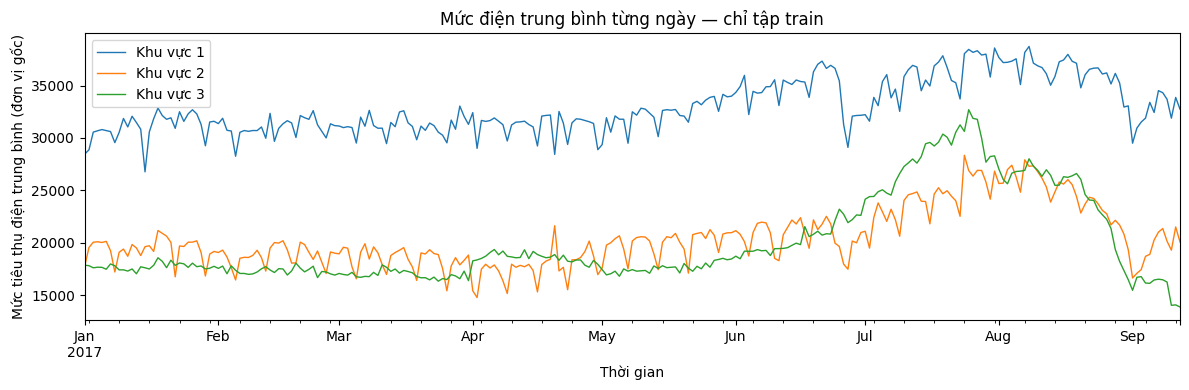

In [60]:
train_view = df.iloc[:train_end]  # Chỉ lấy các dòng train, không lấy validation hay test.
daily_power = train_view.set_index('time')[zones].resample('D').mean()  # Tính mức điện trung bình từng ngày để biểu đồ dễ nhìn.
daily_power.plot(figsize=(12, 4), linewidth=1)  # Vẽ ba đường, mỗi đường ứng với một khu vực.
plt.title('Mức điện trung bình từng ngày — chỉ tập train')  # Ghi rõ nội dung và phạm vi biểu đồ.
plt.xlabel('Thời gian')  # Trục ngang là ngày đo.
plt.ylabel('Mức tiêu thụ điện trung bình (đơn vị gốc)')  # Giữ nguyên đơn vị của dữ liệu.
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])  # Gắn tên cho ba đường.
plt.tight_layout()  # Căn bố cục để không che nhãn.
plt.show()  # Hiện biểu đồ trong notebook.


### EDA — Kiểm tra và xem dữ liệu train
Kiểm tra dữ liệu trước, sau đó mỗi ô code hiện một bảng riêng để dễ đọc. Các bảng thống kê chỉ dùng train.


In [61]:
assert df.notna().all().all() and np.isfinite(df[weather + zones]).all().all()  # Dừng nếu có ô thiếu hoặc số vô hạn trong phần phát triển.
assert not df.time.duplicated().any()  # Dừng nếu có hai dòng trùng thời điểm.
assert df.time.diff().dropna().eq(pd.Timedelta(minutes=10)).all()  # Kiểm tra các dòng liên tiếp cách nhau đúng 10 phút.


### Thống kê chung của train


In [62]:
early = df.iloc[:train_end]  # Chỉ lấy phần train để xem thống kê.
display(early[weather + zones].describe().T)  # Hiện trung bình, nhỏ nhất, lớn nhất và các mốc phân bố.


,count,mean,std,min,25%,50%,75%,max
temperature,"36,691.0000",19.2393,6.1815,3.2470,14.3400,19.1600,24.0400,40.0100
humidity,"36,691.0000",67.6561,16.0826,11.3400,57.3800,69.5200,81.4000,93.6000
wind_speed,"36,691.0000",1.9980,2.3575,0.0500,0.0770,0.0860,4.9130,4.9780
general_diffuse,"36,691.0000",207.6599,285.7269,0.0040,0.0660,18.2100,383.2000,"1,163.0000"
diffuse,"36,691.0000",86.5442,135.8819,0.0190,0.1260,16.4400,119.8000,936.0000
zone_1,"36,691.0000","32,956.8892","7,255.5949","13,895.6962","26,703.4233","33,089.3617","38,195.8804","52,204.3951"
zone_2,"36,691.0000","20,444.8429","5,067.7250","8,560.0815","16,298.7573","20,444.3506","23,875.6239","37,408.8608"
zone_3,"36,691.0000","20,024.4123","6,464.3840","8,189.9081","15,290.1818","18,071.6308","24,821.5674","47,598.3264"


### Mức điện trung bình theo giờ
Ba đường cho ba khu vực, chỉ dùng train. Mỗi điểm là trung bình của khung giờ đó trên tất cả các ngày train; ví dụ điểm 20 giờ gồm các số đo 20:00–20:50. Đây là nhịp trong ngày, không phải diễn biến của một ngày riêng lẻ.


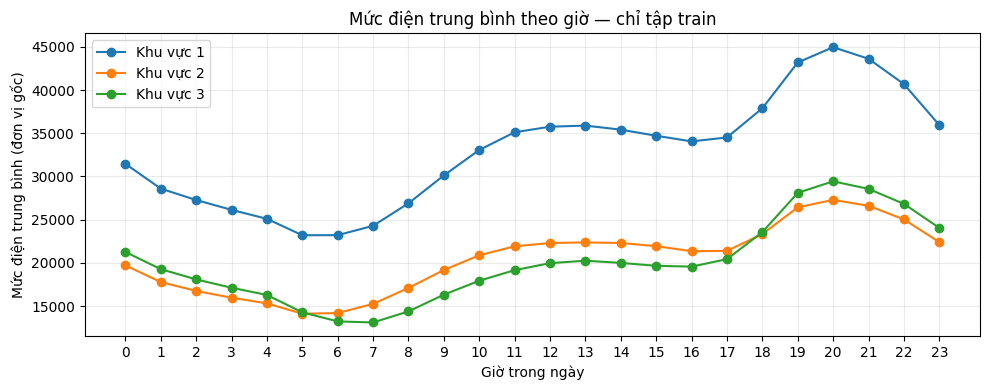

In [63]:
hourly_power = early.groupby(early.time.dt.hour)[zones].mean()  # Tính mức điện trung bình của từng khung giờ trên train.
hourly_power.plot(marker='o', figsize=(10, 4))  # Vẽ ba đường với 24 điểm cho ba khu vực.
plt.title('Mức điện trung bình theo giờ — chỉ tập train')  # Ghi rõ nội dung và phạm vi dữ liệu.
plt.xlabel('Giờ trong ngày')  # Trục ngang là giờ từ 0 đến 23.
plt.ylabel('Mức điện trung bình (đơn vị gốc)')  # Trục dọc giữ đơn vị gốc của số đo.
plt.xticks(range(24))  # Hiện đủ nhãn 24 giờ.
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])  # Phân biệt ba đường theo khu vực.
plt.grid(alpha=0.25)  # Thêm lưới nhạt để dễ đọc giá trị.
plt.tight_layout()  # Căn hình để nhãn không bị che.
plt.show()  # Hiện biểu đồ ngay dưới ô code.


### Mức điện trung bình theo thứ
Mỗi điểm là trung bình các số đo cùng thứ trong train. Mã 0–6 lần lượt là thứ Hai đến Chủ nhật; biểu đồ ghi T2–CN cho dễ đọc. Đây là nhịp chung trong tuần, không phải diễn biến của riêng một tuần.


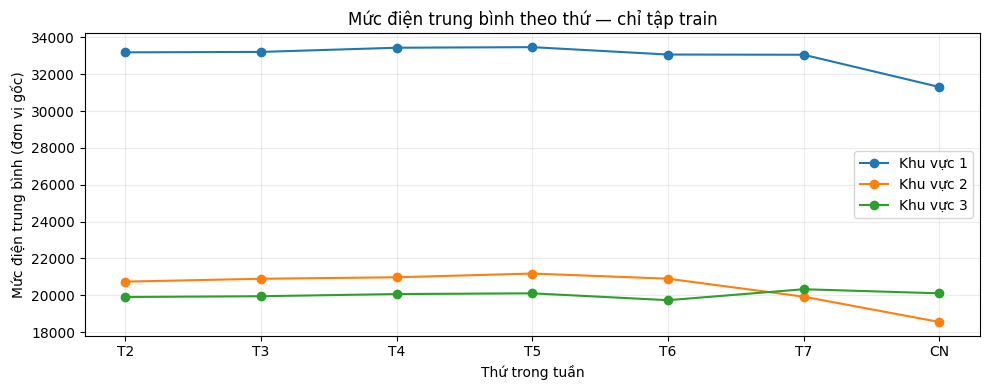

In [64]:
weekday_power = early.groupby(early.time.dt.dayofweek)[zones].mean()  # Gom cùng thứ trong train rồi tính trung bình từng khu vực.
weekday_power.plot(marker='o', figsize=(10, 4))  # Vẽ ba đường, mỗi đường có bảy điểm.
plt.title('Mức điện trung bình theo thứ — chỉ tập train')  # Ghi rõ nội dung biểu đồ.
plt.xlabel('Thứ trong tuần')  # Trục ngang là thứ Hai đến Chủ nhật.
plt.ylabel('Mức điện trung bình (đơn vị gốc)')  # Trục dọc giữ đơn vị gốc của số đo.
plt.xticks(range(7), ['T2', 'T3', 'T4', 'T5', 'T6', 'T7', 'CN'])  # Đổi mã 0–6 thành tên thứ dễ đọc.
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])  # Ghi tên cho ba đường.
plt.grid(alpha=0.25)  # Thêm lưới nhạt để dễ so sánh.
plt.tight_layout()  # Căn hình để nhãn không bị che.
plt.show()  # Hiện biểu đồ dưới ô code.


### Mức điện trung bình theo tháng
Mỗi điểm là mức điện trung bình của một tháng trên train, không phải tổng điện năng. Train chỉ đến 19:00 ngày 12/09/2017 nên tháng 9 chưa đủ tháng; cần đọc điểm cuối thận trọng. Không thêm tháng 10–12 vì chúng nằm ngoài train.


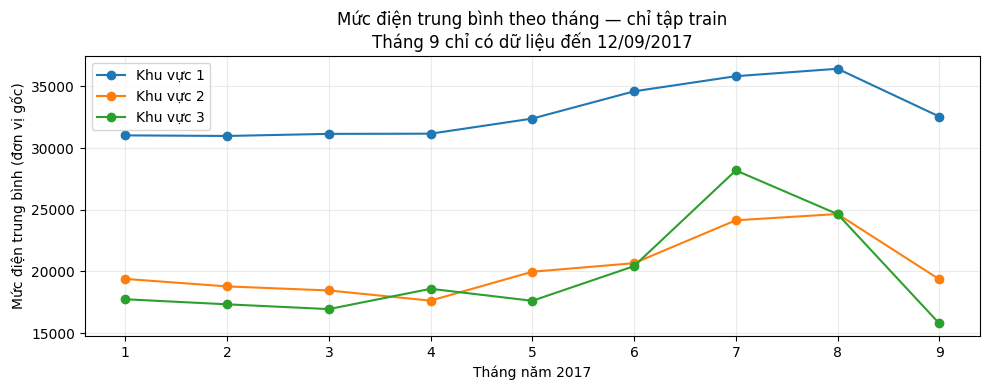

In [65]:
monthly_power = early.groupby(early.time.dt.month)[zones].mean()  # Gom cùng tháng trong train rồi tính trung bình từng khu vực.
monthly_power.plot(marker='o', figsize=(10, 4))  # Vẽ ba đường cho các tháng có trong train.
plt.title('Mức điện trung bình theo tháng — chỉ tập train\nTháng 9 chỉ có dữ liệu đến 12/09/2017')  # Ghi rõ tháng cuối chưa đầy đủ.
plt.xlabel('Tháng năm 2017')  # Trục ngang là tháng của năm dữ liệu.
plt.ylabel('Mức điện trung bình (đơn vị gốc)')  # Giữ đơn vị gốc, không cộng thành tổng điện năng.
plt.xticks(monthly_power.index)  # Chỉ hiện các tháng thực sự có dữ liệu train.
plt.legend(['Khu vực 1', 'Khu vực 2', 'Khu vực 3'])  # Ghi tên cho ba đường.
plt.grid(alpha=0.25)  # Thêm lưới nhạt để dễ đọc.
plt.tight_layout()  # Căn hình để nhãn không bị che.
plt.show()  # Hiện biểu đồ dưới ô code.


## 3. Cách làm ban đầu — chỉ 8 số đo hiện tại
X gồm 5 số đo thời tiết/bức xạ và điện hiện tại của 3 khu vực. y là điện ba khu vực sau 10 phút.
Chưa thêm lag, trung bình hay sin/cos. Giữ cố định các thời điểm đánh giá từ lúc đáp án đủ một tháng lịch sử, vì phần sau sẽ thử lịch sử tháng.
Đây là cách giữ cùng đề kiểm tra cho mọi bước; không chọn thời điểm dựa trên số điện hoặc sai số.


In [66]:
horizon = 1  # Dự đoán một dòng kế tiếp.
time_step = df.time.diff().dropna().mode().iloc[0]  # Lấy khoảng cách thời gian phổ biến: 10 phút.
steps_per_day = int(pd.Timedelta(days=1) / time_step)  # Một ngày có 144 bước.
raw_columns = weather + zones  # Tám đầu vào hiện tại, chưa có lịch sử.
evaluation_start = df.time.iloc[0] + pd.DateOffset(months=1)  # Giữ cùng mốc đủ lịch sử cho các bước sau.
target_time = df.time + horizon * time_step  # Thời điểm cần dự đoán.
y = df[zones].shift(-horizon)  # Đưa số điện dòng sau về làm đáp án dòng hiện tại.
valid = (target_time >= evaluation_start) & y.notna().all(axis=1)  # Chỉ giữ mốc chung có đủ đáp án.
X, y = df.loc[valid, raw_columns], y.loc[valid]  # Lấy đầu vào và đáp án trên cùng các dòng.
origin, target_time = df.time.loc[valid], target_time.loc[valid]  # Giữ giờ dự đoán và giờ có đáp án.
validation_start = df.time.iloc[train_end]  # Mốc bắt đầu validation đã chia lúc đọc.
train = target_time < validation_start  # Đáp án train phải nằm trước validation.
validation = origin >= validation_start  # Validation bắt đầu từ đúng mốc đã chia.
X_train_all, y_train = X.loc[train], y.loc[train]  # Lấy dữ liệu cho mô hình học.
X_val_all, y_val = X.loc[validation], y.loc[validation]  # Lấy dữ liệu chọn phương án.
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)  # Hiện rõ khoảng dự đoán.
print('Train:', len(y_train), '| Validation:', len(y_val))  # Hiện số dòng thực dùng sau khi giữ mốc chung.
assert target_time[train].max() < origin[validation].min()  # Không để đáp án train chạm validation.


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Train: 32227 | Validation: 7861


### Chuẩn bị test để đối chiếu từng bước
Chỉ tạo đầu vào và đáp án để chấm; không fit mô hình hay scaler bằng test.
Đánh giá cuốn chiếu: lúc dự đoán đã biết số đo hiện tại, chưa biết dòng tiếp theo.


In [67]:
test.columns = df.columns  # Dùng cùng tên cột như phần phát triển.
test['time'] = pd.to_datetime(test['time'], format='%m/%d/%Y %H:%M')  # Đọc ngày giờ test đúng định dạng gốc.
assert test.time.diff().dropna().eq(time_step).all()  # Kiểm tra test vẫn cách nhau 10 phút.
assert test.time.iloc[0] - df.time.iloc[-1] == time_step  # Kiểm tra ranh giới không bị đứt đoạn.
assert test.notna().all().all() and np.isfinite(test[weather + zones]).all().all()  # Dừng nếu test không chấm được do thiếu hoặc vô hạn.
X_test_all = test[raw_columns].iloc[:-horizon].copy()  # Chỉ dùng các số đo đã biết tại mỗi mốc.
y_test = test[zones].shift(-horizon).iloc[:-horizon]  # Dòng kế tiếp là đáp án để chấm.
test_origin = test.time.iloc[:-horizon]  # Giờ bắt đầu dự đoán từng dòng test.
test_target_time = test_origin + horizon * time_step  # Giờ đáp án tương ứng.
assert target_time[validation].max() < test_origin.min()  # Đáp án validation không lấn vào đầu vào test.
print('Số dòng test được chấm:', len(y_test))  # Dòng cuối không có đáp án kế tiếp nên không chấm.


Số dòng test được chấm: 7862


### Cách chấm dùng chung
MAE là độ lệch trung bình, càng nhỏ càng tốt. RMSE nhấn mạnh lỗi lớn; MAPE là phần trăm sai số; R² không phải phần trăm chính xác.
MAE/RMSE/MAPE tính chung ba khu vực, R² trung bình điểm từng khu vực. Hai hàm dưới giúp các bước chấm và hiện bảng theo cùng một cách.


In [68]:
def metrics(truth, predicted):  # Viết hàm chấm điểm dùng chung cho mọi mô hình.
    return [mean_absolute_error(truth, predicted),  # Tính MAE: độ lệch tuyệt đối trung bình.
            np.sqrt(mean_squared_error(truth, predicted)),  # Tính RMSE: chỉ tiêu nhạy hơn với lỗi lớn.
            mean_absolute_percentage_error(truth, predicted) * 100,  # Tính MAPE rồi đổi sang phần trăm.
            r2_score(truth, predicted)]  # Tính R² trung bình của ba khu vực.

metric_names = ['MAE', 'RMSE', 'MAPE (%)', 'R2']  # Đặt tên bốn cột điểm theo đúng thứ tự tính.

result_rows, step_tables = [], []  # Giữ điểm từng cấu hình và từng bước để xuất báo cáo.
val_predictions, train_predictions, test_predictions = {}, {}, {}  # Giữ dự đoán để tính điểm và vẽ.
candidates, candidate_columns = {}, {}  # Giữ mô hình được xét chọn cùng đầu vào tương ứng.
extra_models, extra_columns, delta_names = {}, {}, set()  # Chuẩn bị chỗ cho các thử nghiệm sau.
result_columns = ['Model', 'Số biến'] + ['Validation ' + m for m in metric_names]  # Tên cột validation.
result_columns += ['Train ' + m for m in metric_names] + ['Test ' + m for m in metric_names]  # Thêm tên cột train/test.

def record_result(name, val_pred, train_pred, test_pred, count, eligible=True):  # Chấm một phương án theo cách thống nhất.
    if eligible:  # Chỉ các phương án được chấp nhận mới tham gia chọn cuối.
        val_predictions[name] = val_pred  # Việc chọn cuối chỉ đọc các dự đoán validation này.
    train_predictions[name], test_predictions[name] = train_pred, test_pred  # Giữ dự đoán gốc để đối chiếu sau.
    result_rows.append([name, count, *metrics(y_val, val_pred), *metrics(y_train, train_pred), *metrics(y_test, test_pred)])  # Tính bốn điểm cho từng tập.

def compare_step(step, names, reference):  # Hiện bảng của một bước tối ưu.
    results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')  # Gom các điểm đã tính thành bảng.
    table = results.loc[names].copy()  # Chỉ lấy các phương án thuộc bước đang học.
    table['Giảm Test MAE so với Persistence'] = results.loc['Persistence', 'Test MAE'] - table['Test MAE']  # Số dương là tốt hơn cách đoán giữ nguyên.
    table['Giảm Test MAE so với ' + reference] = results.loc[reference, 'Test MAE'] - table['Test MAE']  # So với mốc trước của bước này.
    display(table.drop(columns=[c for c in table if c.startswith('Train ') or c in ['Validation RMSE', 'Validation MAPE (%)', 'Validation R2']]))  # Hiện bảng gọn, CSV vẫn giữ đủ điểm.
    step_tables.append(table.reset_index().assign(Bước=step))  # Lưu cả tên bước để làm slide/report.


### Mốc đơn giản nhất: điện 10 phút tới bằng điện hiện tại
Ví dụ hiện tại là 30.000 thì đoán 10 phút sau cũng là 30.000. Chưa cần mô hình học.
Mô hình phải vượt được mốc thực tế này thì việc học mới có ích.


In [69]:
record_result('Persistence', X_val_all[zones].to_numpy(), X_train_all[zones].to_numpy(), X_test_all[zones].to_numpy(), 3)  # Đoán bằng đúng ba số điện hiện tại.
compare_step('Mốc giữ nguyên', ['Persistence'], 'Persistence')  # Hiện điểm mốc để so các bước sau.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000


## 4. Mô hình ban đầu — cùng 8 đầu vào
Sáu mô hình: Linear, Ridge, Lasso, KNN, Decision Tree, Random Forest.
Linear học công thức cộng có trọng số; Ridge/Lasso thêm mức phạt; KNN tìm mẫu gần; cây chia điều kiện; rừng gộp nhiều cây.
Chưa tìm tham số, chưa thêm lịch sử. Bộ chuẩn hóa chỉ học trên train.


In [70]:
models = {  # Lập danh sách mô hình cùng cấu hình ban đầu.
    'Linear': make_pipeline(StandardScaler(), LinearRegression()),  # Chuẩn hóa đầu vào rồi dùng hồi quy tuyến tính.
    'Ridge': make_pipeline(StandardScaler(), Ridge(alpha=100)),  # Dùng Ridge với mức phạt Alpha ban đầu là 100.
    'Lasso': make_pipeline(StandardScaler(), Lasso(alpha=10, max_iter=200000, tol=0.001, precompute=True)),  # Dùng Lasso với Alpha ban đầu là 10.
    'KNN': make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=15, weights='distance', n_jobs=2)),  # Dùng 15 mẫu gần nhất, ưu tiên mẫu gần hơn.
    'Decision Tree': DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=42),  # Cây ban đầu sâu tối đa 12, mỗi lá ít nhất 20 mẫu.
    'Random Forest': RandomForestRegressor(n_estimators=60, max_depth=14, min_samples_leaf=5, random_state=42, n_jobs=2),  # Rừng gồm 60 cây, sâu tối đa 14, mỗi lá ít nhất 5 mẫu.
}  # Hoàn tất danh sách sáu mô hình ban đầu.


In [71]:
simple_models = {}  # Giữ riêng các mô hình dùng tám đầu vào.
for name, template in models.items():  # Thử từng loại mô hình với cùng dữ liệu.
    model = clone(template)  # Tạo mô hình mới để không đè bản sẽ dùng ở bước sau.
    model.fit(X_train_all[raw_columns], y_train)  # Chỉ học từ tám số đo hiện tại trong train.
    label = name + ' (8 biến)'  # Ghi rõ đầu vào để không lẫn với bản thêm lịch sử.
    simple_models[label] = model  # Lưu mô hình vừa học.
    candidates[label], candidate_columns[label] = model, raw_columns  # Cho phép xét bản đơn giản ở bước chọn cuối.
    record_result(label, model.predict(X_val_all[raw_columns]), model.predict(X_train_all[raw_columns]), model.predict(X_test_all[raw_columns]), 8)  # Chấm trên cùng các mốc.
compare_step('Mô hình ban đầu', ['Persistence'] + list(simple_models), 'Persistence')  # So tám mô hình với mốc giữ nguyên.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence
Model,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456
Ridge (8 biến),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338
Lasso (8 biến),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166
KNN (8 biến),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154"
Decision Tree (8 biến),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011"
Random Forest (8 biến),8,873.5496,"1,914.0566","2,671.8124",11.1645,0.6796,"-1,620.9436"


## 5. Tối ưu 1 — thêm quá khứ và giờ trong ngày
Chỉ biết số hiện tại có thể chưa biết điện đang tăng hay giảm. Thêm các số điện trước đó, trung bình và độ dao động gần đây.
Hàm dưới chuẩn bị cả nhóm tuần/tháng để bước sau dùng; bước này chỉ cho Linear dùng nhóm ngắn hạn 40 biến.

Vì sao có sin/cos? 23 giờ và 0 giờ thực tế chỉ cách một giờ, nhưng hai con số lại chênh 23. Đặt thời gian lên mặt đồng hồ tròn để cuối ngày nối với đầu ngày.
Hai tọa độ sin/cos mô tả vị trí trên vòng tròn; dùng một tọa độ có thể làm hai thời điểm khác nhau trùng nhau. Thứ trong tuần cũng là vòng tròn.
Đây là cách mã hóa chu kỳ thông dụng, không bảo đảm mọi mô hình đều tăng điểm. Chưa có thử nghiệm riêng để quy toàn bộ mức cải thiện cho sin/cos.


In [72]:
def make_features(frame):  # Tạo một hàm dùng chung để làm đầu vào và đáp án.
    future_time = frame.time + horizon * time_step  # Tính thời điểm cần dự đoán từ thời điểm hiện tại.
    X = frame[weather + zones].copy()  # Bắt đầu bằng số đo thời tiết và điện hiện tại.
    for zone in zones:  # Làm giống nhau cho từng khu vực điện.
        for lag in [1, 3, 6, 18, steps_per_day]:  # Chọn các mốc quá khứ: 10, 30, 60, 180 phút và một ngày.
            X[f'{zone}_lag_{lag}'] = frame[zone].shift(lag)  # Lấy số điện đã đo ở mốc quá khứ đó làm đầu vào.
        for window in [6, 18]:  # Xét nhóm 6 dòng và 18 dòng gần nhất.
            X[f'{zone}_mean_{window}'] = frame[zone].rolling(window).mean()  # Tính điện trung bình của nhóm dòng gần nhất.
            X[f'{zone}_std_{window}'] = frame[zone].rolling(window).std()  # Tính mức dao động điện của nhóm dòng gần nhất.
        X[f'{zone}_daily_reference'] = frame[zone].shift(steps_per_day - horizon)  # Lấy điện cùng giờ với đáp án, nhưng ở hôm trước.
        X[f'{zone}_weekly_lag'] = frame[zone].shift(7 * steps_per_day)  # Lấy điện đúng một tuần trước thời điểm hiện tại.
        X[f'{zone}_weekly_reference'] = frame[zone].shift(7 * steps_per_day - horizon)  # Lấy điện cùng giờ với đáp án, nhưng ở tuần trước.
        previous_month = future_time - pd.DateOffset(months=1)  # Lùi giờ cần đoán về cùng ngày, giờ của tháng trước.
        X[f'{zone}_monthly_reference'] = previous_month.map(frame.set_index('time')[zone])  # Tra số điện đã đo tại mốc tháng trước vừa tìm.
    minute = future_time.dt.hour * 60 + future_time.dt.minute  # Đổi giờ cần đoán thành số phút tính từ đầu ngày.
    X['clock_sin'] = np.sin(2 * np.pi * minute / 1440)  # Biểu diễn giờ bằng sin để nối cuối ngày với đầu ngày.
    X['clock_cos'] = np.cos(2 * np.pi * minute / 1440)  # Thêm cos để phân biệt đầy đủ các vị trí trong ngày.
    X['weekday_sin'] = np.sin(2 * np.pi * future_time.dt.dayofweek / 7)  # Biểu diễn thứ trong tuần bằng sin.
    X['weekday_cos'] = np.cos(2 * np.pi * future_time.dt.dayofweek / 7)  # Thêm cos để giữ đúng vòng lặp bảy ngày.
    X['is_weekend'] = (future_time.dt.dayofweek >= 5).astype(float)  # Đánh dấu thứ Bảy, Chủ nhật là 1; ngày khác là 0.
    X['month_sin'] = np.sin(2 * np.pi * (future_time.dt.month - 1) / 12)  # Biểu diễn tháng trong năm bằng sin.
    X['month_cos'] = np.cos(2 * np.pi * (future_time.dt.month - 1) / 12)  # Thêm cos để nối tháng 12 với tháng 1.
    phase = (future_time.dt.day - 1) / future_time.dt.days_in_month  # Tính vị trí của ngày trong tháng, bắt đầu từ 0.
    X['month_day_sin'] = np.sin(2 * np.pi * phase)  # Biểu diễn vị trí trong tháng bằng sin.
    X['month_day_cos'] = np.cos(2 * np.pi * phase)  # Thêm cos để mô tả vòng lặp trong tháng.
    y = frame[zones].shift(-horizon)  # Lấy điện ở dòng kế tiếp làm đáp án để học và chấm.
    valid = X.notna().all(axis=1) & y.notna().all(axis=1)  # Chỉ giữ dòng có đủ đầu vào và đủ đáp án.
    return X.loc[valid], y.loc[valid], frame.time.loc[valid], future_time.loc[valid]  # Trả lại đầu vào, đáp án, lúc dự đoán và lúc đáp án.

X, y, origin, target_time = make_features(df)  # Tạo các bảng từ phần train và validation.
print('Time step:', time_step, '| Dự đoán trước:', horizon * time_step)  # Hiện khoảng cách dữ liệu và khoảng dự đoán trước.
print('Số đầu vào khi có cả tuần và tháng:', X.shape[1])  # Đếm số đầu vào khi thêm cả tuần và tháng.
display(X.head(2))  # Hiện hai dòng đầu vào đã được tạo.


Time step: 0 days 00:10:00 | Dự đoán trước: 0 days 00:10:00
Số đầu vào khi có cả tuần và tháng: 56


,temperature,humidity,wind_speed,general_diffuse,diffuse,zone_1,zone_2,zone_3,zone_1_lag_1,zone_1_lag_3,...,zone_3_monthly_reference,clock_sin,clock_cos,weekday_sin,weekday_cos,is_weekend,month_sin,month_cos,month_day_sin,month_day_cos
4463,11.4700,69.6300,4.9210,0.0480,0.1520,"31,084.5570","19,225.5319","19,477.5904","31,837.9747","33,685.0633",...,"20,240.9639",0.0000,1.0000,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000
4464,11.5700,66.2600,4.9150,0.0590,0.1190,"29,892.2034","18,729.4833","18,848.8040","31,084.5570","32,688.6076",...,"20,131.0843",0.0436,0.9990,0.9749,-0.2225,0.0000,0.5000,0.8660,0.0000,1.0000


In [73]:
old_train_index, old_val_index, old_test_index = X_train_all.index, X_val_all.index, X_test_all.index  # Giữ mốc ban đầu để kiểm tra so sánh công bằng.
validation_start = df.time.iloc[train_end]  # Giữ nguyên ranh giới đã chia.
train, validation = target_time < validation_start, origin >= validation_start  # Loại đáp án vượt ranh giới train.
X_train_all, y_train = X.loc[train], y.loc[train]  # Lấy train có đủ các nhóm đầu vào.
X_val_all, y_val = X.loc[validation], y.loc[validation]  # Lấy validation ở đúng các mốc cũ.
test_history = pd.concat([df.tail(32 * steps_per_day), test])  # Mượn lịch sử đã biết trước test để tạo đầu vào tháng.
X_test_all, y_test, test_origin, test_target_time = make_features(test_history)  # Tạo đầu vào test bằng cùng công thức.
in_test = test_origin >= test.time.iloc[0]  # Không chấm các dòng lịch sử mượn thêm.
X_test_all, y_test = X_test_all.loc[in_test], y_test.loc[in_test]  # Chỉ giữ các dòng dự đoán thuộc test.
test_origin, test_target_time = test_origin.loc[in_test], test_target_time.loc[in_test]  # Giữ giờ test tương ứng.
assert X_train_all.index.equals(old_train_index) and X_val_all.index.equals(old_val_index)  # Train và validation phải đúng các dòng ban đầu.
assert X_test_all.index.equals(old_test_index)  # Test cũng phải đúng các dòng ban đầu.
weekly = [c for c in X if 'weekly_' in c or c.startswith('weekday_') or c == 'is_weekend']  # Nhận diện nhóm tuần.
monthly = [c for c in X if 'monthly_' in c or c.startswith('month_')]  # Nhận diện nhóm tháng.
short = [c for c in X if c not in weekly + monthly]  # Nhóm ngắn hạn chưa có tuần/tháng.
short_model = make_pipeline(StandardScaler(), LinearRegression())  # Giữ cùng Linear để đo tác động của đầu vào.
short_model.fit(X_train_all[short], y_train)  # Học lại với 40 đầu vào ngắn hạn.
candidates['Linear (40 biến)'], candidate_columns['Linear (40 biến)'] = short_model, short  # Lưu mô hình và đúng cột nó đã học.
record_result('Linear (40 biến)', short_model.predict(X_val_all[short]), short_model.predict(X_train_all[short]), short_model.predict(X_test_all[short]), len(short))  # Chấm trên đúng các dòng cũ.
compare_step('Thêm quá khứ và giờ', ['Persistence', 'Linear (8 biến)', 'Linear (40 biến)'], 'Linear (8 biến)')  # So trước/sau, chưa kết luận riêng tác dụng sin/cos.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (8 biến)
Model,,,,,,,,
Persistence,3,295.4928,293.1130,456.7377,1.4608,0.9915,0.0000,8.4456
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Linear (40 biến),40,166.4142,178.6915,278.4380,0.9275,0.9965,114.4215,122.8672


## 6. Tối ưu 2 — chọn đầu vào riêng cho sáu mô hình
Mỗi mô hình thử bốn nhóm: ngắn hạn, thêm tuần, thêm tháng, thêm cả hai. Giữ cấu hình ban đầu để chỉ đổi đầu vào.
Chọn nhóm bằng MAE validation của chính mô hình đó. Đoạn này chỉ hiện validation, không tính điểm hay hiện bảng test.
Bảng so với bản tám biến nằm ở phần dưới, sau khi đã chốt sáu nhóm riêng. Nhóm tốt nhất ở cấu hình ban đầu chưa chắc tốt nhất với mọi tham số khác.


In [74]:
feature_sets = {'Ngắn hạn': short, '+ Tuần': short + weekly, '+ Tháng': short + monthly, '+ Tuần và tháng': list(X.columns)}  # Bốn nhóm đầu vào cho từng mô hình.
season_rows, season_models = [], {}  # Giữ điểm validation và các mô hình đã học.
for model_name, template in models.items():  # Lần lượt thử đủ sáu mô hình.
    for group_name, columns in feature_sets.items():  # Mỗi mô hình thử đủ bốn nhóm.
        model = clone(template)  # Tạo mô hình chưa học với cấu hình ban đầu.
        model.fit(X_train_all[columns], y_train)  # Chỉ học từ train với nhóm cột đang thử.
        error = mean_absolute_error(y_val, model.predict(X_val_all[columns]))  # Chỉ chấm validation, không dùng test.
        season_models[model_name, group_name] = model  # Giữ mô hình theo cả tên và nhóm đầu vào.
        season_rows.append([model_name, group_name, len(columns), error])  # Lưu một trong 24 kết quả.
seasonality = pd.DataFrame(season_rows, columns=['Model', 'Nhóm đầu vào', 'Số biến', 'Validation MAE'])  # Bảng đầy đủ 24 cặp mô hình và nhóm.
selected_groups, model_columns, selected_rows = {}, {}, []  # Mỗi mô hình có lựa chọn riêng.
for name in models:  # Chọn độc lập cho từng mô hình.
    table = seasonality.loc[seasonality['Model'] == name]  # Lấy bốn kết quả của mô hình này.
    best = table.loc[table['Validation MAE'].idxmin()]  # Lấy hàng có MAE validation nhỏ nhất.
    group = best['Nhóm đầu vào']  # Đọc tên nhóm được chọn.
    selected_groups[name], model_columns[name] = group, feature_sets[group]  # Giữ tên nhóm và đúng danh sách cột.
    selected_rows.append(best)  # Giữ một hàng được chọn cho mỗi mô hình.
selected_features = pd.DataFrame(selected_rows).set_index('Model')  # Bảng sáu lựa chọn riêng.
display(seasonality.pivot(index='Model', columns='Nhóm đầu vào', values='Validation MAE'))  # So bốn nhóm bằng validation cho sáu mô hình.
display(selected_features)  # Hiện nhóm tốt nhất trong bốn nhóm của từng mô hình.


Nhóm đầu vào,+ Tháng,+ Tuần,+ Tuần và tháng,Ngắn hạn
Model,,,,
Decision Tree,"1,116.6321","1,118.3675","1,118.7698","1,116.9190"
KNN,"1,677.3792","1,837.1900","1,801.4908","1,619.4868"
Lasso,221.0035,223.5357,224.7901,222.2190
Linear,168.1104,163.7002,165.4323,166.4142
Random Forest,941.0476,941.2051,948.5444,939.0575
Ridge,225.6683,210.9964,220.0876,215.7443


,Nhóm đầu vào,Số biến,Validation MAE
Model,,,
Linear,+ Tuần,49,163.7002
Ridge,+ Tuần,49,210.9964
Lasso,+ Tháng,47,221.0035
KNN,Ngắn hạn,40,"1,619.4868"
Decision Tree,+ Tháng,47,"1,116.6321"
Random Forest,Ngắn hạn,40,939.0575


### Đối chiếu đầu vào được chọn với bản tám biến
Tái dùng sáu mô hình đã học trên nhóm được chọn riêng, giữ cả các bản tám biến để so sánh.
Bảng đối chiếu nằm tại đây, không lặp ở đoạn chọn nhóm phía trên. Test chỉ đối chiếu sau lựa chọn, không dùng để đổi nhóm.
Thêm ba mốc cùng giờ hôm qua, tuần trước, tháng trước để tham khảo.


In [75]:
baseline_columns = {  # Các mốc đoán đơn giản dùng để đối chiếu.
    'Persistence': zones,  # Giữ nguyên điện hiện tại.
    'Previous day': [f'{z}_daily_reference' for z in zones],  # Lấy điện cùng giờ hôm qua.
    'Previous week': [f'{z}_weekly_reference' for z in zones],  # Lấy điện cùng giờ tuần trước.
    'Previous month': [f'{z}_monthly_reference' for z in zones]  # Lấy điện cùng ngày giờ tháng trước.
}
for name, columns in baseline_columns.items():  # Ghi điểm các mốc đối chiếu.
    if name != 'Persistence':  # Persistence đã được ghi ở bước ban đầu.
        record_result(name, X_val_all[columns].to_numpy(), X_train_all[columns].to_numpy(), X_test_all[columns].to_numpy(), len(columns))  # Chấm các mốc trên cùng thời điểm.
for name in models:  # Lấy phương án đầu vào đã chọn riêng cho sáu mô hình.
    columns = model_columns[name]  # Dùng đúng các cột đã chọn bằng validation.
    model = season_models[name, selected_groups[name]]  # Tái dùng mô hình đã học, không học lại.
    candidates[name], candidate_columns[name] = model, columns  # Giữ mô hình và bộ đầu vào tương ứng.
    record_result(name, model.predict(X_val_all[columns]), model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns))  # Chấm sau khi đã chốt nhóm đầu vào.
initial_results = pd.DataFrame([[name, *metrics(y_val, val_predictions[name])] for name in models], columns=['Model'] + metric_names).set_index('Model')  # Điểm validation sau khi chọn đầu vào riêng.
compare_step('Đầu vào chọn riêng từng mô hình', list(simple_models) + list(models), 'Linear (8 biến)')  # Giữ bảng đối chiếu với các bản tám biến ở đây.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear (8 biến)
Model,,,,,,,,
Linear (8 biến),8,313.1016,301.5586,453.2010,1.4963,0.9918,-8.4456,0.0000
Ridge (8 biến),8,338.6927,357.4468,499.8253,1.7941,0.9899,-64.3338,-55.8882
Lasso (8 biến),8,299.0746,301.2296,453.7627,1.5274,0.9916,-8.1166,0.3290
KNN (8 biến),8,"1,721.7479","2,869.1284","3,513.6079",17.3113,0.2190,"-2,576.0154","-2,567.5697"
Decision Tree (8 biến),8,"1,103.8269","2,224.0141","2,952.2267",12.7374,0.6075,"-1,930.9011","-1,922.4555"
Random Forest (8 biến),8,873.5496,"1,914.0566","2,671.8124",11.1645,0.6796,"-1,620.9436","-1,612.4980"
Linear,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,128.0277
Ridge,49,210.9964,255.5105,366.1971,1.3066,0.9940,37.6025,46.0481
Lasso,47,221.0035,268.1456,384.9544,1.3524,0.9938,24.9674,33.4131


## 7. Tối ưu 3 — tìm tham số
Giữ bộ đầu vào đã chọn riêng cho từng mô hình, thử cấu hình bằng ba lượt CV theo thời gian trong train, chừa một dòng ở ranh giới.
Chọn tham số theo CV MAE; sau mỗi nhóm hiện điểm trước/sau trên validation và test. Không chỉnh tham số dựa vào test.
Danh sách cấu hình hữu hạn, không gọi là tối ưu tuyệt đối. Bản tìm tham số có thể kém hơn bản đầu trên validation/test.


In [76]:
cv = TimeSeriesSplit(n_splits=3, gap=horizon)  # Ba lượt theo thời gian, chừa một bước ranh giới.
tuned, searches, tuning_rows = {}, {}, []  # Giữ mô hình và kết quả tìm tham số.

def tune_model(name, grid):  # Tìm tham số với đầu vào riêng đã chọn cho mô hình.
    columns = model_columns[name]  # Không dùng nhóm của Linear cho các mô hình khác.
    search = GridSearchCV(models[name], grid, scoring='neg_mean_absolute_error', cv=cv, n_jobs=1, error_score='raise')  # Chọn tham số bằng CV MAE trên train.
    search.fit(X_train_all[columns], y_train)  # Chỉ học và chuẩn hóa trong các lượt train.
    model = search.best_estimator_  # Lấy mô hình với tham số đã chọn.
    tuned[name], searches[name] = model, search  # Giữ mô hình và chi tiết tìm kiếm.
    label = name + ' (tuned)'  # Phân biệt với bản chưa tìm tham số.
    candidates[label], candidate_columns[label] = model, columns  # Giữ đúng các cột cho lần dự đoán sau.
    val_pred = model.predict(X_val_all[columns])  # Dự đoán validation với cùng bộ cột.
    record_result(label, val_pred, model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns))  # Lưu điểm để so trước và sau.
    tuning_rows.append([name, selected_groups[name], search.best_params_, -search.best_score_, mean_absolute_error(y_val, val_pred)])  # Ghi cả nhóm đầu vào tương ứng.
    print(name, '| Nhóm:', selected_groups[name], '| Tham số:', search.best_params_, '| CV MAE:', -search.best_score_)  # Hiện cấu hình được chọn.
    compare_step('Tìm tham số - ' + name, [name, label], name)  # So bản đầu và bản đã tìm tham số.


### Ridge và Lasso
Tên ridge__alpha nghĩa là chỉnh Alpha của bước Ridge bên trong pipeline. Lasso dùng tương tự.


In [77]:
tune_model('Ridge', {'ridge__alpha': [0.001, 0.1, 1, 10, 100, 1000]})  # Thử sáu giá trị Alpha cho Ridge trong pipeline.
tune_model('Lasso', {'lasso__alpha': [0.1, 1, 10, 100]})  # Thử bốn giá trị Alpha cho Lasso trong pipeline.


Ridge | Nhóm: + Tuần | Tham số: {'ridge__alpha': 0.001} | CV MAE: 185.91970627293196


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Ridge
Model,,,,,,,,
Ridge,49,210.9964,255.5105,366.1971,1.3066,0.9940,37.6025,0.0000
Ridge (tuned),49,163.7004,173.5318,271.3373,0.8951,0.9967,119.5812,81.9787


Lasso | Nhóm: + Tháng | Tham số: {'lasso__alpha': 0.1} | CV MAE: 204.227378008203


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Lasso
Model,,,,,,,,
Lasso,47,221.0035,268.1456,384.9544,1.3524,0.9938,24.9674,0.0000
Lasso (tuned),47,182.5659,197.9172,303.1945,1.0875,0.9952,95.1958,70.2284


### KNN và đồ thị K
Chọn K bằng MAE nhỏ nhất trên CV. Đường cong để nhìn xu hướng, không đoán K bằng mắt.


KNN | Nhóm: Ngắn hạn | Tham số: {'kneighborsregressor__n_neighbors': 9} | CV MAE: 1306.0138827723174


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với KNN
Model,,,,,,,,
KNN,40,"1,619.4868","2,935.7419","3,322.9152",17.1139,0.3995,"-2,642.6289",0.0000
KNN (tuned),40,"1,580.1727","2,823.2522","3,249.4287",16.2388,0.4510,"-2,530.1392",112.4897


,K,CV MAE
0,3,"1,326.9997"
1,5,"1,311.3698"
2,9,"1,306.0139"
3,15,"1,311.5358"
4,21,"1,321.0308"
5,31,"1,336.0023"


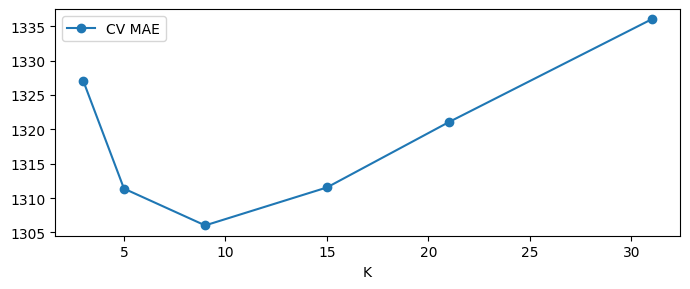

In [78]:
tune_model('KNN', {'kneighborsregressor__n_neighbors': [3, 5, 9, 15, 21, 31]})  # Thử sáu giá trị K và chọn bằng MAE CV.
search = searches['KNN']  # Lấy lại kết quả tìm K vừa chạy.
k_scores = pd.DataFrame({'K': search.cv_results_['param_kneighborsregressor__n_neighbors'],  # Lấy danh sách K đã thử để lập bảng.
                         'CV MAE': -search.cv_results_['mean_test_score']})  # Đổi điểm CV dấu âm thành MAE dương dễ đọc.
display(k_scores)  # Hiện K và độ sai tương ứng.
k_scores.plot(x='K', y='CV MAE', marker='o', figsize=(7, 3))  # Vẽ đường cong MAE theo K.
plt.tight_layout()  # Chỉnh khoảng trống để nhãn không bị cắt.
plt.show()  # Hiện biểu đồ để nhìn xu hướng khi K thay đổi.


### Cây và rừng
Chạy tìm tham số cho cả hai. Rừng giữ 60 cây để thời gian chạy vừa phải.


In [79]:
tune_model('Decision Tree', {'max_depth': [6, 12, 18, None], 'min_samples_leaf': [5, 20]})  # Thử độ sâu và số mẫu tối thiểu ở lá của cây.
tune_model('Random Forest', {'max_depth': [10, 18, None], 'min_samples_leaf': [2, 10]})  # Thử độ sâu và số mẫu tối thiểu ở lá của rừng.


Decision Tree | Nhóm: + Tháng | Tham số: {'max_depth': None, 'min_samples_leaf': 5} | CV MAE: 968.4418684281394


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Decision Tree
Model,,,,,,,,
Decision Tree,47,"1,116.6321","2,153.5567","2,997.9611",12.3426,0.6073,"-1,860.4437",0.0000
Decision Tree (tuned),47,"1,034.2399","1,969.3330","2,894.5425",10.7910,0.6597,"-1,676.2200",184.2236


Random Forest | Nhóm: Ngắn hạn | Tham số: {'max_depth': None, 'min_samples_leaf': 2} | CV MAE: 743.6879072149413


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Random Forest
Model,,,,,,,,
Random Forest,40,939.0575,"1,954.2987","2,818.6677",11.0177,0.6670,"-1,661.1857",0.0000
Random Forest (tuned),40,906.5497,"1,865.9388","2,713.3682",10.3759,0.6967,"-1,572.8258",88.3599


### Tổng hợp tìm tham số
Gom kết quả của Ridge, Lasso, KNN, Decision Tree và Random Forest.


In [80]:
tuning_results = pd.DataFrame(tuning_rows, columns=['Model', 'Nhóm đầu vào', 'Tham số chọn', 'CV MAE', 'Validation MAE'])  # Gom kết quả năm mô hình có tìm tham số.
display(tuning_results)  # Hiện nhóm đầu vào và tham số của từng mô hình.


,Model,Nhóm đầu vào,Tham số chọn,CV MAE,Validation MAE
0,Ridge,+ Tuần,{'ridge__alpha': 0.001},185.9197,163.7004
1,Lasso,+ Tháng,{'lasso__alpha': 0.1},204.2274,182.5659
2,KNN,Ngắn hạn,{'kneighborsregressor__n_neighbors': 9},"1,306.0139","1,580.1727"
3,Decision Tree,+ Tháng,"{'max_depth': None, 'min_samples_leaf': 5}",968.4419,"1,034.2399"
4,Random Forest,Ngắn hạn,"{'max_depth': None, 'min_samples_leaf': 2}",743.6879,906.5497


## 8. Tối ưu 4 — học mức tăng/giảm
Thay vì hỏi điện sắp tới là bao nhiêu, hỏi điện sẽ tăng/giảm bao nhiêu so với hiện tại. Dự đoán xong cộng lại mức hiện tại.
Thử với Random Forest đã tìm tham số; giữ nguyên tham số để chỉ đo tác động đổi đáp án. Chưa tìm tham số riêng cho delta.
Clone tạo mô hình chưa học từ cấu hình rừng đã chọn. Không cắt mức giảm âm.


In [81]:
delta_train = y_train.to_numpy() - X_train_all[zones].to_numpy()  # Lấy điện tương lai trừ mức hiện tại.
delta_names, delta_rows = set(), []  # Giữ tên và điểm của phương án học thay đổi.
for name in ['Random Forest']:  # Thử học phần tăng giảm với rừng.
    columns = model_columns[name]  # Dùng bộ cột được chọn riêng cho Random Forest.
    model = clone(tuned[name])  # Giữ cấu hình đã chọn, tạo mô hình chưa học.
    cv_errors = -cross_val_score(model, X_train_all[columns], delta_train, scoring='neg_mean_absolute_error',  # Chấm mức thay đổi bằng CV.
                                 cv=cv, n_jobs=1, error_score='raise')  # Giữ các lượt chia thời gian trong train.
    model.fit(X_train_all[columns], delta_train)  # Học đáp án mức tăng giảm.
    label = name + ' (delta)'  # Đặt tên để phân biệt với học trực tiếp mức điện.
    predicted = X_val_all[zones].to_numpy() + model.predict(X_val_all[columns])  # Cộng thay đổi vào điện hiện tại trên validation.
    extra_models[label], extra_columns[label] = model, columns  # Giữ mô hình và đúng bộ đầu vào.
    delta_names.add(label)  # Đánh dấu cần cộng mức hiện tại khi dự đoán.
    val_predictions[label] = predicted  # Lưu dự đoán đã về đơn vị điện gốc.
    before_mae = mean_absolute_error(y_val, val_predictions[name + ' (tuned)'])  # Điểm trước khi đổi đáp án.
    candidates[label], candidate_columns[label] = model, columns  # Đưa phương án vào danh sách xét chọn.
    record_result(label, predicted, X_train_all[zones].to_numpy() + model.predict(X_train_all[columns]), X_test_all[zones].to_numpy() + model.predict(X_test_all[columns]), len(columns))  # Chấm sau khi cộng lại điện hiện tại.
    compare_step('Học mức tăng/giảm - ' + name, [name + ' (tuned)', label], name + ' (tuned)')  # So trước và sau đổi đáp án.
    delta_rows.append([label, before_mae, cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])  # Giữ điểm CV và validation.
delta_results = pd.DataFrame(delta_rows, columns=['Model', 'Validation MAE trước', 'CV MAE delta', 'CV độ lệch chuẩn'] + metric_names).set_index('Model')  # Gom điểm của phương án delta.
display(delta_results)  # Hiện kết quả đối chiếu.


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Random Forest (tuned)
Model,,,,,,,,
Random Forest (tuned),40,906.5497,"1,865.9388","2,713.3682",10.3759,0.6967,"-1,572.8258",0.0000
Random Forest (delta),40,191.3375,247.7419,375.4480,1.2691,0.9942,45.3711,"1,618.1969"


,Validation MAE trước,CV MAE delta,CV độ lệch chuẩn,MAE,RMSE,MAPE (%),R2
Model,,,,,,,
Random Forest (delta),906.5497,254.5722,56.9274,191.3375,295.8678,0.9357,0.9961


## 9. Tối ưu 5 — thử bỏ nhóm đầu vào
Nhiều đầu vào chưa chắc tốt. Giữ cùng Linear, cùng CV, cùng thời điểm; thử bỏ từng nhóm và một tập gọn.
Chỉ nhận phương án giảm biến nếu cả CV MAE và validation MAE đều thấp hơn bản giữ nguyên. Đây là quy tắc thực dụng, không phải kiểm định thống kê.
Hiện cả điểm test của các phương án để đối chiếu; không đổi quy tắc dựa trên test.


In [82]:
selected_columns = model_columns['Linear']  # Phần bỏ biến này chỉ xét bộ đầu vào riêng của Linear.
removals = {  # Liệt kê sáu nhóm đầu vào sẽ thử bỏ riêng từng nhóm.
    'Bỏ thời tiết': weather,  # Thử bỏ năm cột thời tiết.
    'Bỏ độ lệch chuẩn': [c for c in selected_columns if '_std_' in c],  # Thử bỏ các cột đo mức dao động gần đây.
    'Bỏ trung bình': [c for c in selected_columns if '_mean_' in c],  # Thử bỏ các cột trung bình điện gần đây.
    'Bỏ cả nhóm rolling': [c for c in selected_columns if '_std_' in c or '_mean_' in c],  # Thử bỏ cả trung bình và độ dao động gần đây.
    'Bỏ lag 3/6/18': [f'{z}_lag_{lag}' for z in zones for lag in [3, 6, 18]],  # Thử bỏ điện trước 30 phút, 1 giờ và 3 giờ của ba khu vực.
    'Bỏ lịch sử tuần': [c for c in selected_columns if '_weekly_' in c]  # Thử bỏ số điện tham chiếu theo tuần, vẫn giữ thứ và cuối tuần.
}  # Chốt danh sách những nhóm cần thử bỏ.
ablation_columns = {'Giữ nguyên': selected_columns}  # Giữ một phương án đủ đầu vào để làm mốc so sánh.
for name, removed in removals.items():  # Lần lượt xét từng nhóm định bỏ.
    ablation_columns[name] = [c for c in selected_columns if c not in removed]  # Tạo bộ cột còn lại sau khi bỏ nhóm đang xét.
compact = zones + [f'{z}_lag_{lag}' for z in zones for lag in [1, 3]]  # Bắt đầu tập gọn bằng điện hiện tại, trước 10 phút và trước 30 phút.
compact += [c for c in selected_columns if '_mean_' in c]  # Giữ thêm trung bình điện gần đây trong tập gọn.
compact += ['clock_sin', 'clock_cos', 'weekday_sin', 'weekday_cos', 'is_weekend']  # Giữ giờ, thứ và thông tin cuối tuần.
compact += [f'{z}_daily_reference' for z in zones] + [f'{z}_weekly_reference' for z in zones]  # Giữ điện đúng khung giờ cần đoán của hôm trước và tuần trước.
compact = [c for c in dict.fromkeys(compact) if c in selected_columns]  # Chỉ giữ cột thuộc nhóm Linear đã chọn.
ablation_columns['Tập gọn'] = compact  # Thêm tập gọn vào danh sách phương án cần thử.
feature_models, feature_predictions, feature_rows = {}, {}, []  # Chuẩn bị chỗ giữ mô hình, dự đoán và bảng điểm của từng phương án.
for name, columns in ablation_columns.items():  # Lần lượt thử mọi phương án đầu vào đã liệt kê.
    model = make_pipeline(StandardScaler(), LinearRegression())  # Ghép chuẩn hóa đầu vào với Linear để các phương án được học giống nhau.
    cv_errors = -cross_val_score(model, X_train_all[columns], y_train,  # Chấm ba lượt trong train; đổi điểm âm của thư viện thành MAE dương.
                                 scoring='neg_mean_absolute_error', cv=cv, error_score='raise')  # Chia theo thời gian, chấm bằng MAE; có lỗi thì dừng.
    model.fit(X_train_all[columns], y_train)  # Học lại Linear bằng toàn bộ train với đúng bộ cột đang thử.
    predicted = model.predict(X_val_all[columns])  # Dùng bộ cột đó để dự đoán validation.
    feature_models[name], feature_predictions[name] = model, predicted  # Giữ lại mô hình đã học và các số vừa dự đoán.
    record_result('Bỏ biến - ' + name, predicted, model.predict(X_train_all[columns]), model.predict(X_test_all[columns]), len(columns), eligible=False)  # Chấm mọi phương án; chỉ nhận vào chọn cuối nếu đạt quy tắc CV/validation.
    feature_rows.append([name, len(columns), cv_errors.mean(), cv_errors.std(), *metrics(y_val, predicted)])  # Ghi số biến, MAE các lượt CV và bốn điểm đánh giá trên validation.
feature_ablation = pd.DataFrame(feature_rows, columns=['Phương án', 'Số biến', 'CV MAE', 'CV độ lệch chuẩn'] + metric_names).set_index('Phương án')  # Gom điểm thành bảng, lấy tên phương án làm nhãn mỗi hàng.
display(feature_ablation)  # Hiện bảng để đối chiếu đủ biến và các cách giảm biến.
reference = feature_ablation.loc['Giữ nguyên']  # Lấy điểm của phương án giữ nguyên làm mốc.
approved_features = feature_ablation[(feature_ablation['CV MAE'] < reference['CV MAE']) & (feature_ablation.MAE < reference.MAE)]  # Chỉ chấp nhận giảm biến nếu cả CV MAE và validation MAE đều thấp hơn mốc.
# Giữ các mô hình delta từ bước trước, không xóa khi thử bỏ biến.  # Chuẩn bị chỗ chứa các mô hình bổ sung và bộ cột tương ứng.
for name in approved_features.index:  # Chỉ xét những phương án đã đạt cả hai điều kiện.
    label = 'Linear - ' + name  # Đặt tên riêng để nhận ra Linear dùng bộ biến rút gọn.
    extra_models[label], extra_columns[label] = feature_models[name], ablation_columns[name]  # Giữ đúng mô hình và bộ cột đã tạo ra kết quả này.
    val_predictions[label] = feature_predictions[name]  # Cho phương án đạt quy tắc vào chọn cuối.
    candidates[label], candidate_columns[label] = feature_models[name], ablation_columns[name]  # Giữ đúng đầu vào của mô hình được nhận.  # Thêm dự đoán của phương án đạt yêu cầu vào bảng so sánh chung.
print('Cách giảm biến đạt cả hai tiêu chí:', approved_features.index.tolist())  # Thông báo các cách giảm biến đã vượt cả hai tiêu chí.

compare_step('Thử bỏ nhóm đầu vào', ['Bỏ biến - ' + name for name in ablation_columns], 'Linear')  # So với Linear giữ đủ nhóm đã chọn.


,Số biến,CV MAE,CV độ lệch chuẩn,MAE,RMSE,MAPE (%),R2
Phương án,,,,,,,
Giữ nguyên,49,185.9190,14.7062,163.7002,248.1691,0.7952,0.9972
Bỏ thời tiết,44,186.1875,15.3739,163.6213,248.1589,0.7950,0.9972
Bỏ độ lệch chuẩn,43,184.4486,12.1606,163.9602,249.1129,0.7950,0.9971
Bỏ trung bình,43,185.8556,14.7267,163.8047,248.2614,0.7955,0.9972
Bỏ cả nhóm rolling,37,184.4378,12.1992,164.1016,249.2103,0.7954,0.9971
Bỏ lag 3/6/18,40,184.7321,13.1491,164.1011,248.7772,0.7972,0.9971
Bỏ lịch sử tuần,43,190.5180,15.0224,166.3398,250.6944,0.8131,0.9971
Tập gọn,26,242.1579,41.5777,192.7679,290.6699,0.9285,0.9962


Cách giảm biến đạt cả hai tiêu chí: []


,Số biến,Validation MAE,Test MAE,Test RMSE,Test MAPE (%),Test R2,Giảm Test MAE so với Persistence,Giảm Test MAE so với Linear
Model,,,,,,,,
Bỏ biến - Giữ nguyên,49,163.7002,173.5309,271.3365,0.8951,0.9967,119.5821,0.0000
Bỏ biến - Bỏ thời tiết,44,163.6213,174.1249,271.9064,0.8989,0.9966,118.9881,-0.5940
Bỏ biến - Bỏ độ lệch chuẩn,43,163.9602,172.6010,270.2092,0.8912,0.9967,120.5120,0.9299
Bỏ biến - Bỏ trung bình,43,163.8047,173.6740,271.4489,0.8957,0.9967,119.4390,-0.1431
Bỏ biến - Bỏ cả nhóm rolling,37,164.1016,172.8067,270.3721,0.8923,0.9967,120.3063,0.7242
Bỏ biến - Bỏ lag 3/6/18,40,164.1011,174.9067,272.6740,0.9021,0.9966,118.2063,-1.3758
Bỏ biến - Bỏ lịch sử tuần,43,166.3398,178.6225,278.3417,0.9281,0.9965,114.4905,-5.0916
Bỏ biến - Tập gọn,26,192.7679,231.2248,336.4252,1.1917,0.9950,61.8882,-57.6939


## 10. Chốt và tổng hợp
Chọn bằng MAE validation trong các phương án đủ điều kiện. Không chọn mô hình bằng điểm test.
Giữ các bản đơn giản, bản thêm đầu vào, bản tìm tham số và delta để đối chiếu. Các phương án bỏ biến không đạt quy tắc chỉ xuất hiện trong bảng thử nghiệm.


In [83]:
validation_rows = [[name, *metrics(y_val, predicted)] for name, predicted in val_predictions.items()]  # Chỉ chấm các phương án đủ điều kiện chọn.
validation_results = pd.DataFrame(validation_rows, columns=['Model'] + metric_names).set_index('Model').sort_values('MAE')  # Xếp bằng validation, không đọc điểm test.
best_name = validation_results.index[0]  # Chốt phương án có MAE validation nhỏ nhất.
all_results = pd.DataFrame(result_rows, columns=result_columns).set_index('Model')  # Gom kết quả mọi thử nghiệm đã chạy.
train_test_results = all_results.loc[validation_results.index, [c for c in all_results if c.startswith('Train ') or c.startswith('Test ')]]  # Bảng train/test của các ứng viên đủ điều kiện.
best_test_prediction = test_predictions[best_name]  # Lấy dự đoán test có sẵn của phương án đã chọn bằng validation.
display(validation_results)  # Hiện căn cứ chốt mô hình.
display(train_test_results)  # Giữ đủ MAE, RMSE, MAPE và R² của train/test.
print('Chọn bằng validation:', best_name, '| Số dòng test:', len(y_test))  # Nêu rõ tập dùng để chọn.
display(train_test_results.loc[[best_name]])  # Hiện riêng điểm của phương án chốt.
progress_table = pd.concat(step_tables, ignore_index=True)  # Nối bảng từng bước để dùng làm slide/report.
zone_mae = pd.DataFrame({zone: {name: mean_absolute_error(y_test[zone], predicted[:, i]) for name, predicted in test_predictions.items()} for i, zone in enumerate(zones)})  # Chấm riêng từng khu vực để không che lỗi bằng một điểm chung.
display(zone_mae.loc[[best_name, 'Persistence']])  # Đối chiếu mô hình chốt và mốc đơn giản theo khu vực.


,MAE,RMSE,MAPE (%),R2
Model,,,,
Linear,163.7002,248.1691,0.7952,0.9972
Ridge (tuned),163.7004,248.1694,0.7952,0.9972
Linear (40 biến),166.4142,250.8107,0.8133,0.9971
Lasso (tuned),182.5659,272.1750,0.9279,0.9960
Random Forest (delta),191.3375,295.8678,0.9357,0.9961
Ridge,210.9964,313.5944,1.0269,0.9954
Lasso,221.0035,343.2050,1.0557,0.9949
Persistence,295.4928,463.5863,1.3623,0.9910
Lasso (8 biến),299.0746,459.8737,1.4044,0.9910


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967
Ridge (tuned),174.8728,280.6289,0.7539,0.9981,173.5318,271.3373,0.8951,0.9967
Linear (40 biến),179.1880,285.6638,0.7730,0.9980,178.6915,278.4380,0.9275,0.9965
Lasso (tuned),196.3784,305.6481,0.8599,0.9977,197.9172,303.1945,1.0875,0.9952
Random Forest (delta),83.0410,149.9439,0.3619,0.9994,247.7419,375.4480,1.2691,0.9942
Ridge,212.8458,331.6777,0.9173,0.9973,255.5105,366.1971,1.3066,0.9940
Lasso,236.5682,375.1909,1.0099,0.9966,268.1456,384.9544,1.3524,0.9938
Persistence,348.0153,523.9934,1.4638,0.9934,293.1130,456.7377,1.4608,0.9915
Lasso (8 biến),328.6891,505.9308,1.3866,0.9938,301.2296,453.7627,1.5274,0.9916


Chọn bằng validation: Linear | Số dòng test: 7862


,Train MAE,Train RMSE,Train MAPE (%),Train R2,Test MAE,Test RMSE,Test MAPE (%),Test R2
Model,,,,,,,,
Linear,174.8728,280.6289,0.7539,0.9981,173.5309,271.3365,0.8951,0.9967


,zone_1,zone_2,zone_3
Linear,220.1709,161.9985,138.4233
Persistence,364.3591,312.3959,202.5840


### 10.1. Đối chứng AR và VAR
So Linear 49 biến với hai mô hình dự báo chuẩn. AR dùng lịch sử điện của chính zone cần dự báo; VAR dùng lịch sử cả ba zone. Cả hai dự báo số điện sau 10 phút.

Dùng cùng các dòng train và cùng thời điểm chấm validation/test với phần trước. Chọn bậc riêng cho AR và VAR bằng ba lượt CV thời gian trong train. Đây là phần đối chiếu bổ sung sau khi chốt mô hình của nhóm.

Nguồn: Hyndman và Athanasopoulos, *Forecasting: Principles and Practice*, [AR](https://otexts.com/fpp3/arima.html#autoregressive-models) và [VAR](https://otexts.com/fpp3/advanced.html#vector-autoregressions).


In [12]:
# Các bậc trễ đem ra so sánh bằng CV.
arvar_orders = [1, 3, 6, 12, 18, 36]
# Ghép lịch sử liên tục để tạo lag; fit chỉ đọc chỉ số thuộc train.
arvar_history = pd.concat([df, test])
# Giữ đúng đáp án và chỉ số các dòng đã chấm trong phần chính.
arvar_y = pd.concat([y_train, y_val, y_test]).sort_index()
arvar_indices = {'Train': y_train.index, 'Validation': y_val.index, 'Test': y_test.index}
assert arvar_history.index.is_unique and arvar_y.index.is_unique
# Kiểm tra đáp án là điện sau một bước, không lệch thời gian.
pd.testing.assert_frame_equal(arvar_history[zones].shift(-horizon).loc[arvar_y.index], arvar_y)

# Lag 0 is the current measurement; lag 1 is ten minutes earlier.
arvar_lags = {}
for zone in zones:
    arvar_lags[zone] = pd.concat(
        [arvar_history[zone].shift(k).rename(f'{zone}_lag_{k}')
         for k in range(max(arvar_orders))], axis=1).loc[arvar_y.index]
    assert arvar_lags[zone].notna().all().all()

# Ghép lịch sử ba zone: bậc p tạo 3p cột đầu vào cho VAR.
def arvar_inputs(order):
    return pd.concat([arvar_lags[zone].iloc[:, :order] for zone in zones], axis=1)

# Fit từng đối chứng bằng hồi quy tuyến tính, scaler học bên trong pipeline.
def fit_arvar(method, order, fit_index):
    if method == 'AR':
        fitted = {}
        for zone in zones:
            model = make_pipeline(StandardScaler(), LinearRegression())
            # AR: X và y chỉ thuộc zone đang xét.
            model.fit(arvar_lags[zone].loc[fit_index].iloc[:, :order],
                      arvar_y.loc[fit_index, zone])
            fitted[zone] = model
        return fitted
    model = make_pipeline(StandardScaler(), LinearRegression())
    # VAR: X là lịch sử cả ba zone, y có ba cột đáp án.
    model.fit(arvar_inputs(order).loc[fit_index], arvar_y.loc[fit_index, zones])
    return model

# Trả ba cột dự đoán theo thứ tự zone_1, zone_2, zone_3.
def predict_arvar(method, order, fitted, index):
    if method == 'AR':
        return np.column_stack([
            fitted[zone].predict(arvar_lags[zone].loc[index].iloc[:, :order])
            for zone in zones])
    return fitted.predict(arvar_inputs(order).loc[index])

display(pd.DataFrame({'Rows': {name: len(index) for name, index in arvar_indices.items()}}))


,Rows
Train,32227
Validation,7861
Test,7862


### 10.2. Chọn bậc trễ
Thử các bậc 1, 3, 6, 12, 18 và 36. Mỗi bậc được chấm bằng MAE trung bình của ba zone qua ba lượt CV thời gian. Scaler chỉ học từ phần train của từng lượt. AR và VAR được chọn riêng theo MAE CV thấp nhất.


In [13]:
# Ba lượt CV mở rộng theo thời gian, gap bằng một dòng.
arvar_cv = TimeSeriesSplit(n_splits=3, gap=horizon)
arvar_cv_rows = []
for method in ['AR', 'VAR']:
    for order in arvar_orders:
        fold_mae = []
        for fold, (fit_positions, score_positions) in enumerate(arvar_cv.split(y_train), start=1):
            # Các dòng để học ở lượt CV này.
            fit_index = y_train.index[fit_positions]
            # Các dòng tương lai để chấm ở lượt CV này.
            score_index = y_train.index[score_positions]
            fitted = fit_arvar(method, order, fit_index)
            prediction = predict_arvar(method, order, fitted, score_index)
            fold_mae.append(mean_absolute_error(arvar_y.loc[score_index, zones], prediction))
        arvar_cv_rows.append([method, order, *fold_mae, np.mean(fold_mae)])
arvar_cv_results = pd.DataFrame(arvar_cv_rows,
    columns=['Model', 'Order', 'Fold 1 MAE', 'Fold 2 MAE', 'Fold 3 MAE', 'CV MAE'])
# Chọn bậc có MAE CV trung bình thấp nhất, riêng từng họ.
arvar_selected = arvar_cv_results.loc[
    arvar_cv_results.groupby('Model')['CV MAE'].idxmin()].set_index('Model')
display(arvar_cv_results.pivot(index='Order', columns='Model', values='CV MAE'))
display(arvar_selected[['Order', 'CV MAE']])


Model,AR,VAR
Order,,
1,350.3129,356.9427
3,232.5867,223.7049
6,231.2147,222.9327
12,230.7398,222.8963
18,231.1177,224.7960
36,231.9202,230.2522


,Order,CV MAE
Model,,
AR,12,230.7398
VAR,12,222.8963


### 10.3. So sánh với Linear
Cả hai tìm kiếm đều chọn bậc 12. Fit lại từng đối chứng trên toàn bộ train, sau đó tính MAE validation và test. AR(12) dùng 12 số đo của chính zone; VAR(12) dùng 36 số đo từ cả ba zone cho mỗi đầu ra. Linear dùng 49 biến đã chọn ở phần trước.


In [14]:
arvar_selected_fits, arvar_predictions = {}, {}
comparison_rows = [
    ['Persistence', mean_absolute_error(y_val, val_predictions['Persistence']),
     mean_absolute_error(y_test, test_predictions['Persistence'])]]
for method in ['AR', 'VAR']:
    # Lấy bậc đã chốt bằng CV, không chọn lại theo test.
    order = int(arvar_selected.loc[method, 'Order'])
    fitted = fit_arvar(method, order, y_train.index)
    arvar_selected_fits[method] = fitted
    scores = []
    # Chấm validation và test sau khi đã chọn bậc.
    for split in ['Validation', 'Test']:
        index = arvar_indices[split]
        prediction = predict_arvar(method, order, fitted, index)
        arvar_predictions[method, split] = prediction
        scores.append(mean_absolute_error(arvar_y.loc[index, zones], prediction))
    comparison_rows.append([f'{method}({order})', *scores])
linear_label = f'Linear ({len(model_columns["Linear"])} inputs)'
comparison_rows.append([linear_label,
    mean_absolute_error(y_val, val_predictions['Linear']),
    mean_absolute_error(y_test, test_predictions['Linear'])])
# Bảng dùng cho report và slide 11.
arvar_comparison = pd.DataFrame(comparison_rows,
    columns=['Model', 'Validation MAE', 'Test MAE']).set_index('Model')
display(arvar_comparison)
for method in ['AR', 'VAR']:
    label = f'{method}({int(arvar_selected.loc[method, "Order"])})'
    # Tỷ lệ giảm = 100 × (1 − MAE Linear / MAE đối chứng).
    reduction = 100 * (1 - arvar_comparison.loc[linear_label, 'Test MAE'] /
                       arvar_comparison.loc[label, 'Test MAE'])
    print(f'Linear test MAE reduction vs {label}: {reduction:.1f}%')


,Validation MAE,Test MAE
Model,,
Persistence,295.4928,293.1130
AR(12),203.3488,208.0750
VAR(12),196.2484,226.5171
Linear (49 inputs),163.7002,173.5309


Linear test MAE reduction vs AR(12): 16.6%
Linear test MAE reduction vs VAR(12): 23.4%


Linear có MAE test 173,53; AR(12) là 208,07 và VAR(12) là 226,52. Linear giảm sai số lần lượt 16,6% và 23,4%, đồng thời có MAE validation thấp hơn cả hai. Kết quả cho thấy lợi ích của bộ 49 biến: lịch sử điện gần và theo chu kỳ, thống kê trượt, lịch và thời tiết hiện tại.

VAR tốt hơn AR trên CV và validation nhưng kém hơn trên test. Thêm lịch sử các zone khác không giúp mọi giai đoạn. Kết luận dựa trên những cấu hình và cách chia đang xét.


## 11. Sai số theo thời gian
Hai biểu đồ đường theo tuần và tháng, so Persistence với ba phương án tốt nhất theo validation. Mỗi điểm là MAE chung ba khu vực trong kỳ, gắn với giờ đáp án. Tuần/tháng đầu và cuối có thể chưa đủ kỳ. Không hiện bảng số ở mục này; CSV vẫn được lưu.


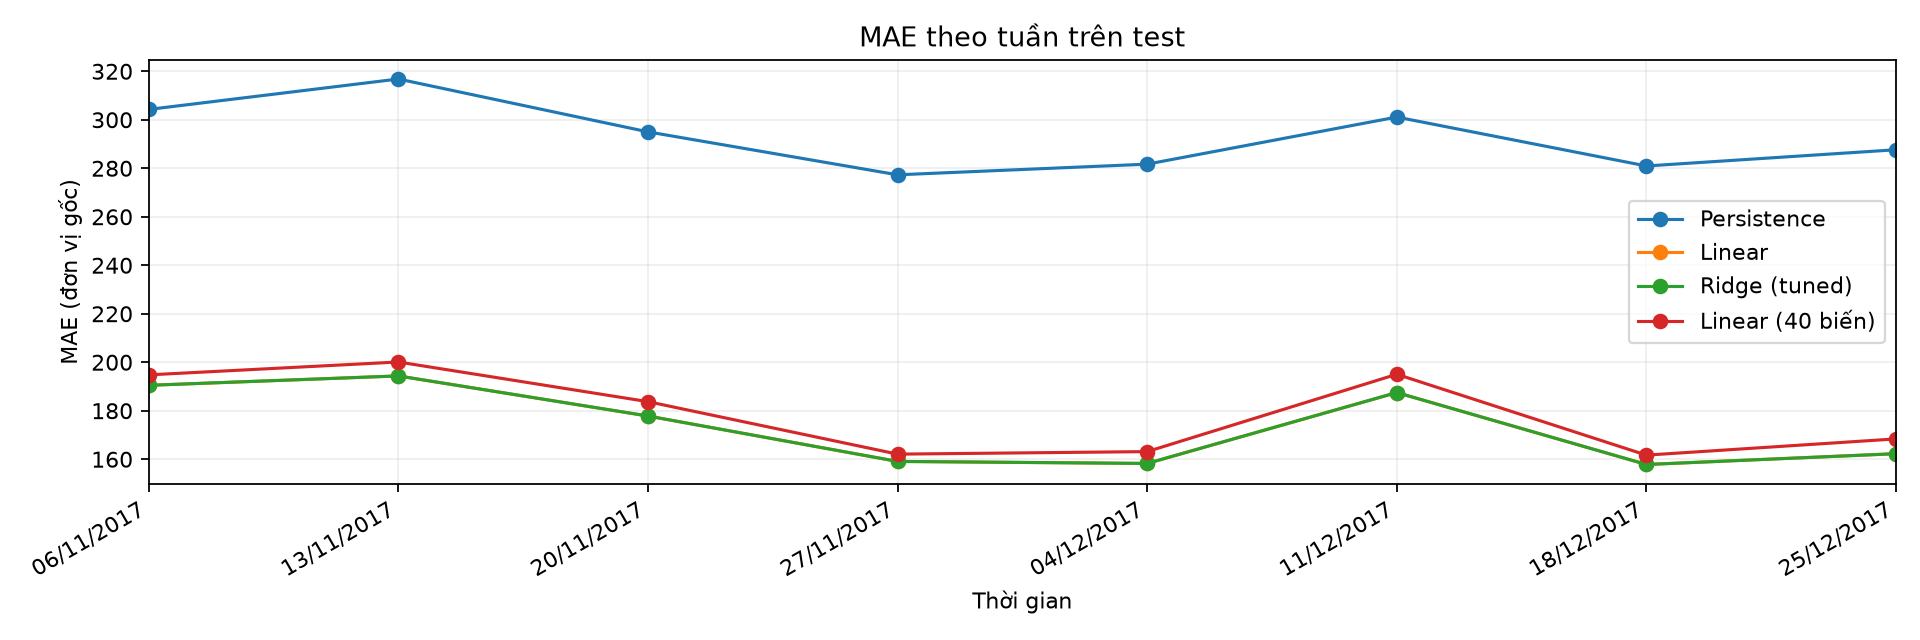

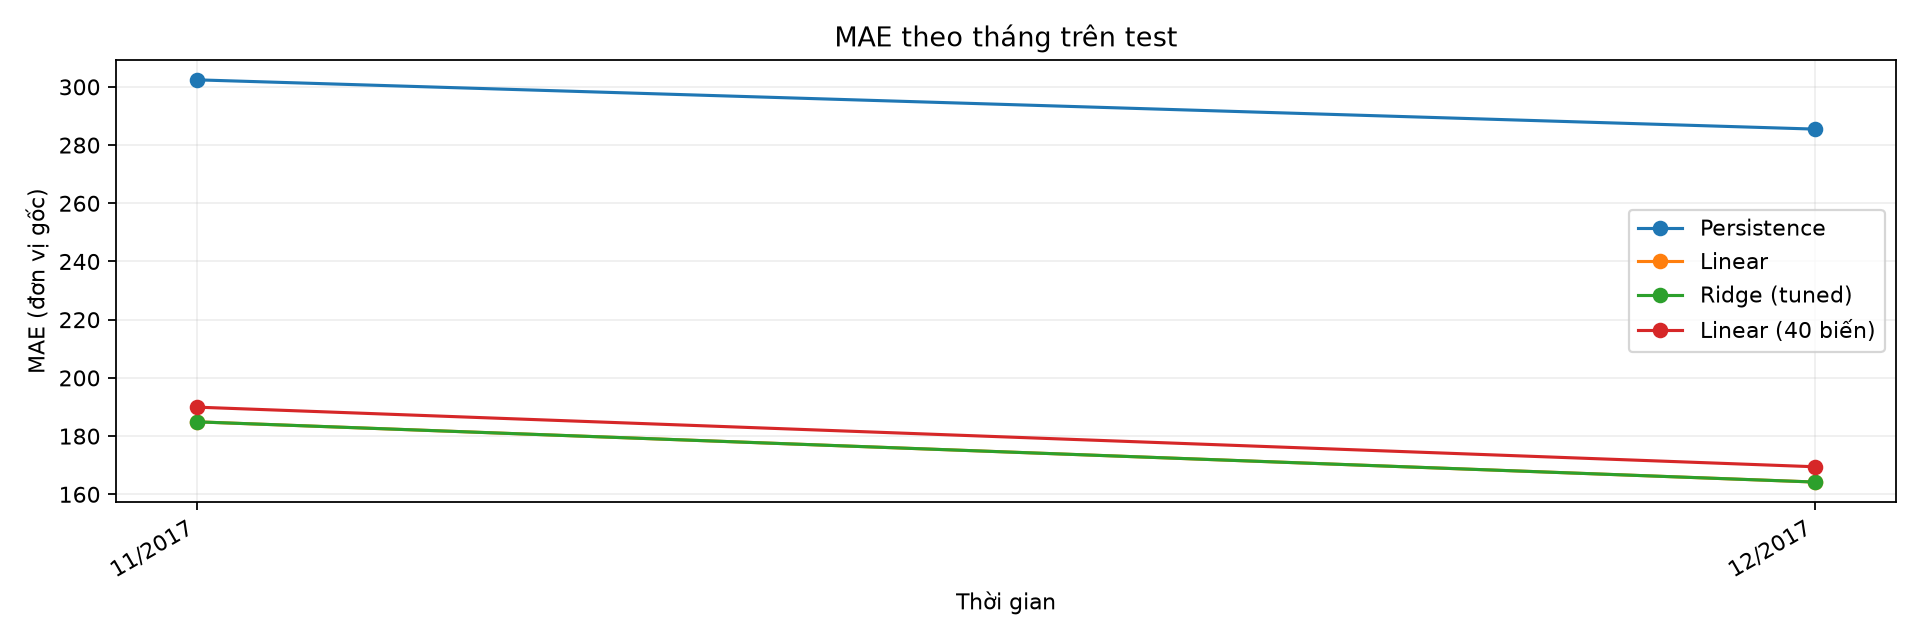

In [ ]:
row_errors = {name: np.abs(y_test.to_numpy() - predicted).mean(axis=1)  # Tính MAE ba khu vực ở từng thời điểm.
              for name, predicted in test_predictions.items()}  # Giữ sai số theo từng phương án.
errors_by_time = pd.DataFrame(row_errors, index=pd.DatetimeIndex(test_target_time, name='Thời điểm đáp án'))  # Gắn sai số với giờ đáp án.
weekly_mae = errors_by_time.groupby(errors_by_time.index.to_period('W')).mean()  # Tính MAE trung bình mỗi tuần.
monthly_mae = errors_by_time.groupby(errors_by_time.index.to_period('M')).mean()  # Tính MAE trung bình mỗi tháng.
show_models = list(dict.fromkeys(['Persistence'] + validation_results.index[:3].tolist()))  # So mốc giữ nguyên và ba phương án tốt nhất theo validation.
for table, title, filename in [(weekly_mae, 'MAE theo tuần trên test', 'mae_by_week.png'),  # Vẽ sai số tuần.
                               (monthly_mae, 'MAE theo tháng trên test', 'mae_by_month.png')]:  # Vẽ sai số tháng.
    view = table[show_models].copy()  # Lấy các đường cần đối chiếu.
    view.index = view.index.to_timestamp()  # Đổi nhãn tuần hoặc tháng thành mốc ngày để vẽ.
    ax = view.plot(figsize=(12, 4), marker='o', linewidth=1.4)  # Mỗi phương án là một đường.
    ax.set(title=title, xlabel='Thời gian', ylabel='MAE (đơn vị gốc)')  # Ghi rõ trục và cách tính sai số.
    date_format = '%m/%Y' if filename == 'mae_by_month.png' else '%d/%m/%Y'  # Dùng nhãn tháng hoặc ngày phù hợp.
    ax.set_xticks(view.index)  # Chỉ đặt nhãn tại các điểm có số liệu.
    ax.set_xticklabels(view.index.strftime(date_format))  # Hiện ngày theo cách ghi quen thuộc.
    ax.grid(alpha=0.2)  # Thêm lưới nhẹ để đọc giá trị.
    ax.figure.autofmt_xdate()  # Xoay nhãn ngày cho dễ đọc.
    ax.figure.tight_layout()  # Căn khoảng cách chữ và biểu đồ.
    ax.figure.savefig(filename, dpi=160)  # Lưu hình tuần hoặc tháng.
    plt.show()  # Hiện biểu đồ đường thay bảng số.
plot_zone = 'zone_1'  # Chọn khu vực cho hai hình thực tế và dự đoán.
zone_index = zones.index(plot_zone)  # Tìm vị trí cột của khu vực được chọn.
timeline = pd.DataFrame({'Lúc dự đoán': test_origin.to_numpy(), 'Lúc đáp án': test_target_time.to_numpy(),  # Giữ hai mốc thời gian.
                         'Thực tế': y_test[plot_zone].to_numpy(), 'Dự đoán': best_test_prediction[:, zone_index]})  # Ghép đúng số thật và dự đoán, không hiện bảng từng mẫu.


## 12. Biểu đồ hai đường: thực tế và dự đoán
Ba hình: ba giờ đầu test, một ngày đầu test và toàn bộ test. Cùng mô hình, khu vực và dữ liệu 10 phút, không gộp trung bình. Đây là các cửa sổ hiển thị; mỗi dự đoán vẫn trước 10 phút.
Đổi plot_zone ở phần 11 nếu muốn xem khu vực khác. Hai đường cùng gắn với thời điểm đáp án.

### 3 giờ đầu test


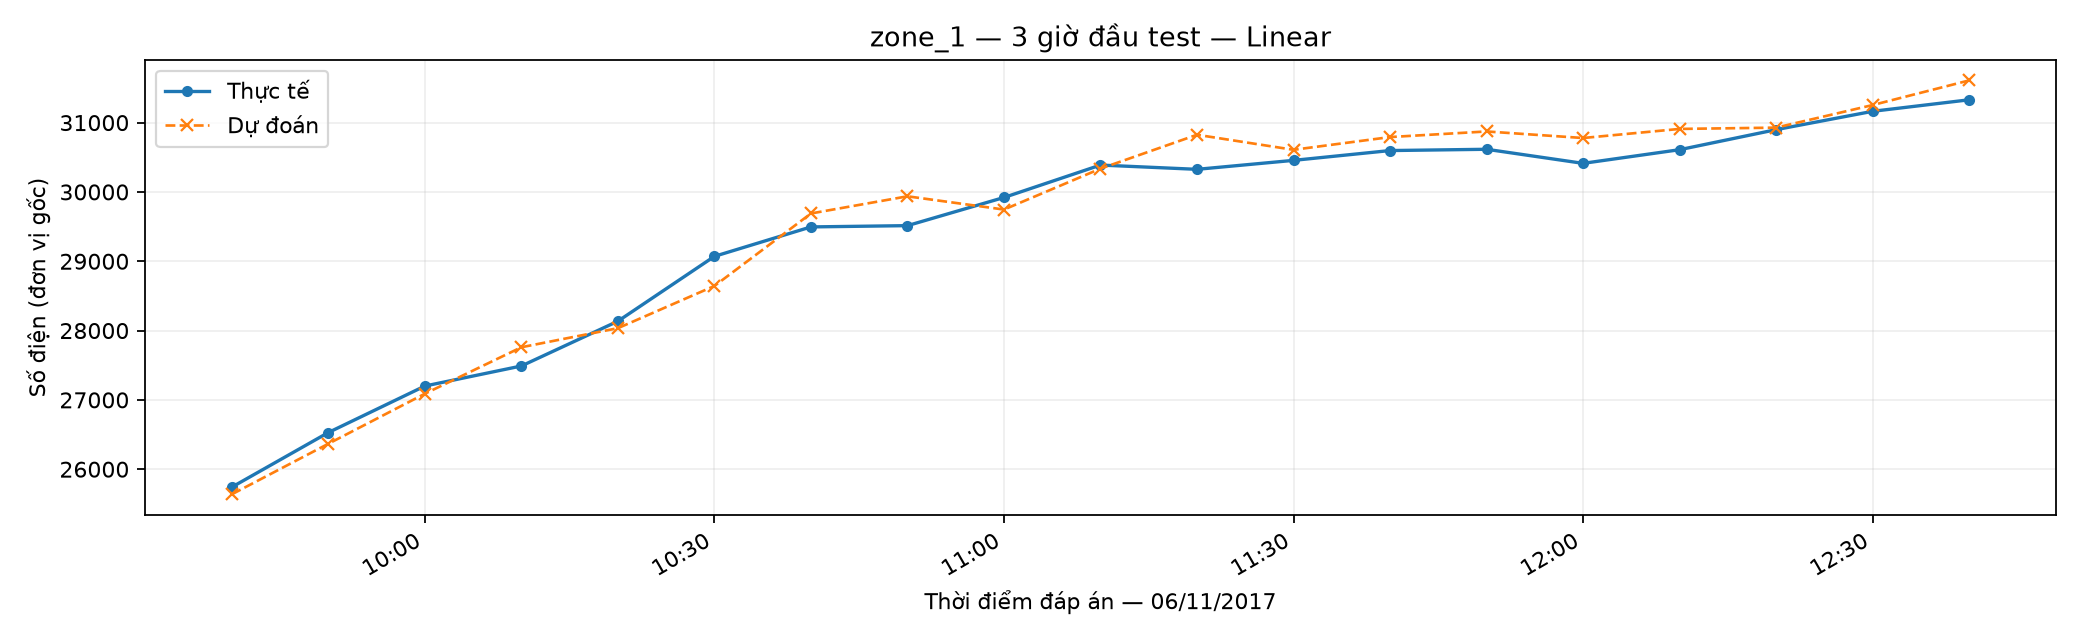

In [ ]:
from matplotlib.dates import DateFormatter  # Định dạng nhãn giờ cho hình phóng gần.
shown = timeline[timeline['Lúc đáp án'] <= timeline['Lúc đáp án'].iloc[0] + pd.Timedelta(hours=3)]  # Giữ ba giờ đầu, gồm hai đầu mút.
fig, ax = plt.subplots(figsize=(13, 4))  # Tạo vùng vẽ.
ax.plot(shown['Lúc đáp án'], shown['Thực tế'], label='Thực tế', linewidth=1.5, marker='o', markersize=4)  # Đánh dấu từng số điện thật.
ax.plot(shown['Lúc đáp án'], shown['Dự đoán'], label='Dự đoán', linewidth=1.2, linestyle='--', marker='x', markersize=5)  # Vẽ dự đoán bằng nét đứt và dấu x.
ax.set(title=f'{plot_zone} — 3 giờ đầu test — {best_name}', xlabel='Thời điểm đáp án — ' + shown['Lúc đáp án'].iloc[0].strftime('%d/%m/%Y'), ylabel='Số điện (đơn vị gốc)')  # Ghi rõ ngày và cửa sổ hiển thị.
ax.xaxis.set_major_formatter(DateFormatter('%H:%M'))  # Trục ngang hiện giờ và phút.
ax.grid(alpha=0.2)  # Thêm lưới nhẹ.
ax.legend()  # Phân biệt hai đường.
fig.autofmt_xdate()  # Căn nhãn giờ.
fig.tight_layout()  # Căn bố cục.
fig.savefig('next_step_forecast_3h.png', dpi=160)  # Lưu hình ba giờ.
plt.show()  # Hiện hình phóng gần.


### 1 ngày đầu test
Hiện 24 giờ liên tiếp từ thời điểm đáp án đầu tiên để nhìn nhịp trong ngày, không phải đổi sang dự đoán trước một ngày.


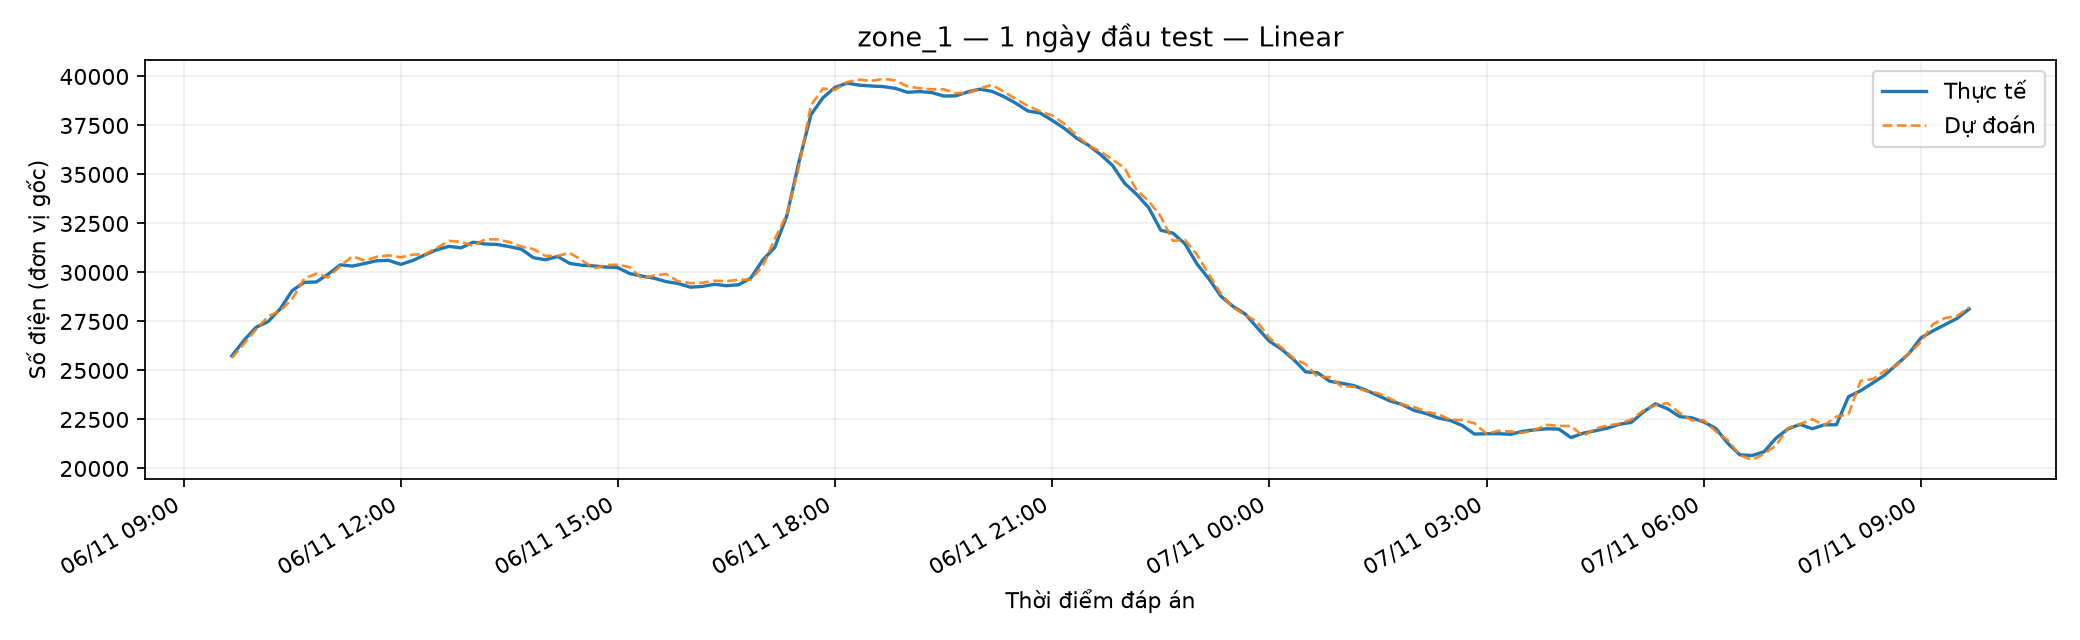

In [ ]:
from matplotlib.dates import DateFormatter  # Định dạng nhãn ngày giờ.
shown_day = timeline[timeline['Lúc đáp án'] <= timeline['Lúc đáp án'].iloc[0] + pd.Timedelta(days=1)]  # Lấy trọn 24 giờ đầu test.
fig, ax = plt.subplots(figsize=(13, 4))  # Tạo hình riêng cho một ngày.
ax.plot(shown_day['Lúc đáp án'], shown_day['Thực tế'], label='Thực tế', linewidth=1.5)  # Vẽ số điện thật.
ax.plot(shown_day['Lúc đáp án'], shown_day['Dự đoán'], label='Dự đoán', linewidth=1.2, linestyle='--', alpha=0.9)  # Vẽ dự đoán cùng các thời điểm.
ax.set(title=f'{plot_zone} — 1 ngày đầu test — {best_name}', xlabel='Thời điểm đáp án', ylabel='Số điện (đơn vị gốc)')  # Ghi rõ cửa sổ một ngày.
ax.xaxis.set_major_formatter(DateFormatter('%d/%m %H:%M'))  # Hiện cả ngày khi đi qua nửa đêm.
ax.grid(alpha=0.2)  # Thêm lưới nhẹ để so hai đường.
ax.legend()  # Hiện chú giải.
fig.autofmt_xdate()  # Căn nhãn ngày giờ.
fig.tight_layout()  # Căn bố cục.
fig.savefig('next_step_forecast_1day.png', dpi=160)  # Lưu hình một ngày.
plt.show()  # Hiện hình 24 giờ.


### Toàn bộ tập test
Hiện tất cả thời điểm có đáp án trong test để xem diễn biến dài hơn. Hai hình phóng gần phía trên giúp xem độ lệch từng đoạn; phạm vi chấm điểm vẫn là toàn bộ test.


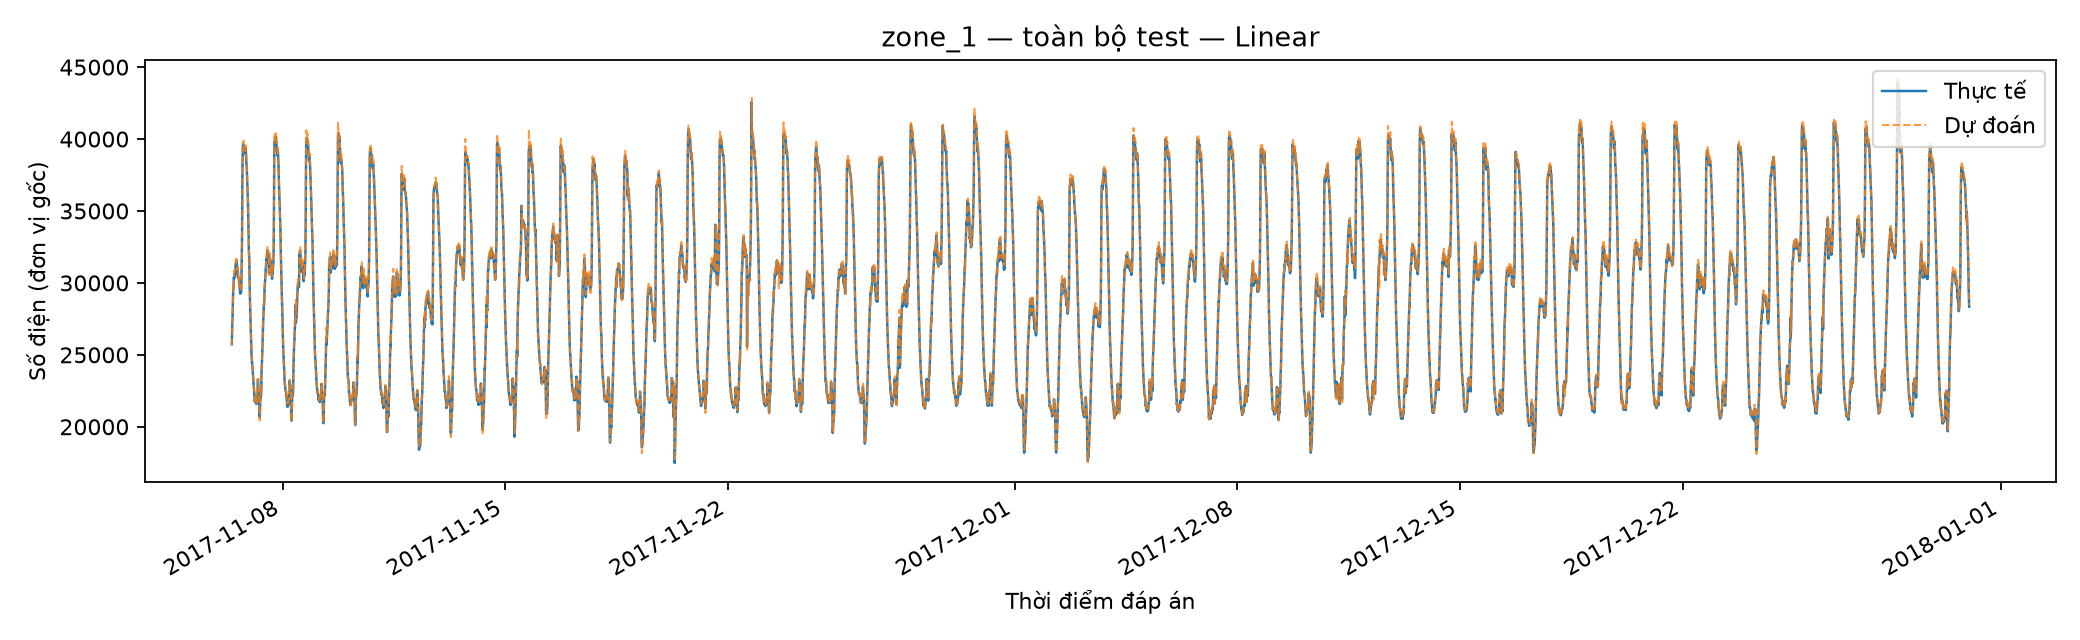

In [ ]:
fig, ax = plt.subplots(figsize=(13, 4))  # Tạo hình riêng cho toàn bộ test.
ax.plot(timeline['Lúc đáp án'], timeline['Thực tế'], label='Thực tế', linewidth=1.1)  # Vẽ mọi bản ghi thật trên test.
ax.plot(timeline['Lúc đáp án'], timeline['Dự đoán'], label='Dự đoán', linewidth=0.9, linestyle='--', alpha=0.8)  # Vẽ dự đoán đúng các thời điểm đó.
ax.set(title=f'{plot_zone} — toàn bộ test — {best_name}', xlabel='Thời điểm đáp án', ylabel='Số điện (đơn vị gốc)')  # Ghi rõ phạm vi toàn test.
ax.legend()  # Phân biệt số thật và dự đoán.
fig.autofmt_xdate()  # Căn nhãn ngày.
fig.tight_layout()  # Căn bố cục hình.
fig.savefig('next_step_forecast_full_test.png', dpi=160)  # Lưu hình toàn bộ test.
plt.show()  # Hiện hình mới bên cạnh hình bảy ngày.


## 13. Lưu kết quả
Các bảng CSV và ảnh được tạo lại khi chạy. Bảng optimization_progression.csv giữ kết quả từng bước; bảng all_experiment_results.csv giữ mọi cấu hình đã thử.
Kết luận dựa vào bảng chạy thật, kể cả bước không cải thiện. Thêm mô hình, tham số hoặc tháng không bảo đảm tốt hơn.


In [ ]:
feature_ablation.to_csv('feature_ablation_comparison.csv')  # Lưu bảng thử giảm biến để đối chiếu số cột và điểm đánh giá.
delta_results.to_csv('delta_target_comparison.csv')  # Lưu bảng so sánh học số điện trực tiếp với học mức tăng giảm.
seasonality.to_csv('seasonality_comparison.csv', index=False)  # Lưu bảng thử thông tin theo tuần và tháng, bỏ cột số thứ tự.
validation_results.to_csv('validation_model_comparison.csv')  # Lưu bảng validation đã dùng để chọn phương án.
tuning_results.to_csv('tuning_comparison.csv', index=False)  # Lưu kết quả tìm tham số của các mô hình.
train_test_results.to_csv('train_test_model_comparison.csv')  # Lưu bảng điểm train và test để kiểm tra độ lệch giữa hai giai đoạn.
weekly_mae.to_csv('mae_by_week.csv')  # Lưu bảng MAE theo tuần.
monthly_mae.to_csv('mae_by_month.csv')  # Lưu bảng MAE theo tháng.
forecast_table = pd.DataFrame({'origin': test_origin.to_numpy(), 'target_time': test_target_time.to_numpy()})  # Tạo bảng chi tiết, mỗi hàng giữ đúng giờ dự đoán và giờ đáp án của test.
for i, zone in enumerate(zones):  # Lần lượt thêm kết quả của ba khu vực theo đúng vị trí cột.
    forecast_table[zone + '_actual'] = y_test[zone].to_numpy()  # Ghi số điện thực tế của khu vực đang xét.
    forecast_table[zone + '_predicted'] = best_test_prediction[:, i]  # Ghi dự đoán của phương án đã chốt cho đúng khu vực đó.
    forecast_table[zone + '_absolute_error'] = np.abs(y_test[zone].to_numpy() - best_test_prediction[:, i])  # Ghi sai số tuyệt đối của từng dự đoán để tra lại được từng hàng.
forecast_table.to_csv('next_step_predictions.csv', index=False)  # Lưu toàn bộ dự đoán test và đáp án của ba khu vực thành CSV.
print('Nhóm đầu vào được chọn riêng:')  # Nhắc lại lựa chọn của sáu mô hình.
display(selected_features)  # Hiện nhóm và MAE validation từng mô hình.
print('Mô hình được chọn trên validation:', best_name)  # Nhắc mô hình được chọn cuối.
selected_features.to_csv('feature_selection_by_model.csv')  # Lưu sáu nhóm đầu vào được chọn.
print('MAE validation:', validation_results.loc[best_name, 'MAE'])  # In MAE validation của phương án đã chốt.
print('MAE test:', train_test_results.loc[best_name, 'Test MAE'])  # In MAE test của chính phương án đó, không đổi sang mô hình khác.
all_results.to_csv('all_experiment_results.csv')  # Lưu cả các phương án thử rồi loại.
progress_table.to_csv('optimization_progression.csv', index=False)  # Lưu bảng trước/sau của từng bước.
zone_mae.to_csv('test_mae_by_zone.csv')  # Lưu sai số riêng cho ba khu vực.
print('Đã lưu các bảng CSV và năm ảnh: mae_by_week.png, mae_by_month.png, next_step_forecast_3h.png, next_step_forecast_1day.png, next_step_forecast_full_test.png.')  # Báo tên các kết quả đã xuất.  # Thông báo đã tạo đủ chín bảng CSV và ảnh biểu đồ.

arvar_cv_results.to_csv('arvar_lag_order_cv.csv', index=False)
arvar_selected.to_csv('arvar_selected_orders.csv')
arvar_comparison.to_csv('arvar_model_comparison.csv')


### Phạm vi, việc chưa thử và nguồn
Dữ liệu chỉ có Tetouan năm 2017. Kết quả không tự động áp dụng cho doanh nghiệp hoặc năm khác.
Test đã được chấm ở các phiên trước và tiếp tục được đối chiếu sau từng bước theo yêu cầu nhóm. Không gọi đây là kiểm chứng trên tập hoàn toàn mới; muốn kiểm chứng độc lập cần dữ liệu tương lai mới.
Các thử nghiệm chọn bằng train/CV/validation. Bảng test có thể giúp mô tả kết quả, không được dùng để chọn các lượt thử tiếp theo.
Chưa thử cây riêng từng khu vực. Linear hiện tại đã có bộ hệ số riêng cho ba đáp án; tách ba lệnh fit với cùng X không phải một cải tiến mới.
Chưa tách thử nghiệm riêng bỏ/giữ sin/cos, nên không quy phần cải thiện chung cho riêng cách mã hóa này.
Metrics theo chương 13. Không ép phân cụm vào bài hồi quy.
Cần đối chiếu yêu cầu chia dữ liệu/ngôn ngữ/template môn học trước khi nộp. Bản này dùng tiếng Việt để nhóm học hiểu.

Nguồn: [UCI Tetouan](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city), [yêu cầu môn học](https://docs.google.com/spreadsheets/d/17AhxqqU-uAUvH9RTIqbgO1w13_obfjTln45ukoH7SmM/edit), [GitHub nhóm](https://github.com/huy1907ddddddd/DS66B_group_14).
